# Real Estate Valuation & Tier Classification: Advanced Machine Learning
### Applied to the Official Kaggle House Prices Dataset (`train.csv`)
**Problem Statement**: Predict the continuous target variable `SalePrice` for residential homes based on continuous and categorical features (`GrLivArea`, `YearBuilt`, `TotalBsmtSF`, `OverallQual`, `Neighborhood`), and classify homes into market tiers.

---

### Core Machine Learning Topics Covered:
1. **Maximum Likelihood Estimation (MLE) & Least Squares Regression**
2. **Robust Linear Regression, Huber Loss & Ridge Regression**
3. **Bayesian Linear Regression & Predictive Distribution Uncertainty**
4. **Linear Models for Classification: Discriminant Functions (OLS, Fisher LDA, Perceptron)**
5. **Probabilistic Generative Models (GDA) vs. Probabilistic Discriminative Models (Logistic)**
6. **Laplace Approximation & Bayesian Logistic Regression**
7. **Support Vector Machine (SVM) Classification (Hyperplanes, Margins, Kernels & Hinge Loss)**
8. **Kernel Functions, Kernel GLM & Support Vector Regression (SVR)**
9. **Comprehensive Model Comparison & Benchmark Summary**


## 0. Environment Setup & Global Utilities
We configure reproducible random seeds, scientific computing libraries, and consistent publication-grade matplotlib visual aesthetics.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, optimize
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LinearRegression, HuberRegressor, Ridge, LogisticRegression, Perceptron
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC, SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, roc_auc_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Set aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 100

np.random.seed(42)
print("Libraries successfully loaded and configured.")


Libraries successfully loaded and configured.


## 0.1 Kaggle Dataset Loading & Preprocessing
We load the official Kaggle Ames Housing dataset (`train.csv` / OpenML `house_prices` ID 42165) containing 1,460 residential properties in Ames, Iowa.

Features extracted for this study:
- `GrLivArea`: Continuous above-grade living area square footage (334 - 5,642 sq ft)
- `YearBuilt`: Continuous/discrete build year (1872 - 2010)
- `TotalBsmtSF`: Continuous basement square footage (collinear with `GrLivArea`)
- `OverallQual`: Overall material and finish quality rating (1 to 10 scale)
- `Neighborhood`: Categorical geographic district in Ames (e.g., `CollgCr`, `NAmes`, `OldTown`, `Edwards`, `Somerst`)
- `SalePrice`: Continuous actual transaction price ($34,900 - $755,000)
- `Luxury_Tier`: Binary classification target ($1$ if `SalePrice` >= 75th percentile / $\$214,000$, else $0$, or $-1$ for SVM/Perceptron)
- Real-World Outliers: The dataset contains Dean De Cock's documented high-leverage outliers (Homes #524 and #1299 with $>4,000$ sq ft that sold for unusually low prices).


In [2]:
# Load local train.csv if present; otherwise fetch directly via openml
csv_path = 'train.csv'
if os.path.exists(csv_path):
    df_raw = pd.read_csv(csv_path)
    print(f"Loaded existing local '{csv_path}' ({df_raw.shape[0]} rows, {df_raw.shape[1]} columns).")
else:
    print("Fetching official Kaggle house_prices dataset from OpenML...")
    dataset = fetch_openml(name='house_prices', as_frame=True, parser='auto')
    df_raw = dataset.frame
    df_raw.to_csv(csv_path, index=False)
    print(f"Downloaded and cached to '{csv_path}' ({df_raw.shape[0]} rows, {df_raw.shape[1]} columns).")

# Select core features and clean missing values
selected_cols = ['GrLivArea', 'YearBuilt', 'TotalBsmtSF', 'OverallQual', 'Neighborhood', 'SalePrice']
df = df_raw[selected_cols].copy()

# Fill any basement missing values with 0
df['TotalBsmtSF'] = df['TotalBsmtSF'].fillna(0)

# Identify famous Ames Housing high-leverage outliers (GrLivArea > 4000 sq ft with low price)
df['IsOutlier'] = ((df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)).astype(int)

# Binary Luxury Tier threshold (Top 25% of the real market: $214,000)
luxury_threshold = df['SalePrice'].quantile(0.75)
df['Luxury_Tier'] = (df['SalePrice'] >= luxury_threshold).astype(int)
df['Luxury_Tier_SVM'] = np.where(df['Luxury_Tier'] == 1, 1, -1)

print(f"\nCleaned Dataset: {len(df)} homes.")
print(f"Luxury Tier Threshold (75th percentile): ${luxury_threshold:,.2f}")
print(f"Luxury homes count: {df['Luxury_Tier'].sum()} | Standard homes count: {(df['Luxury_Tier']==0).sum()}")
print(f"Documented extreme leverage outliers: {df['IsOutlier'].sum()} homes")
display(df.head(5))


Loaded existing local 'train.csv' (1460 rows, 81 columns).

Cleaned Dataset: 1460 homes.
Luxury Tier Threshold (75th percentile): $214,000.00
Luxury homes count: 367 | Standard homes count: 1093
Documented extreme leverage outliers: 2 homes


,GrLivArea,YearBuilt,TotalBsmtSF,OverallQual,Neighborhood,SalePrice,IsOutlier,Luxury_Tier,Luxury_Tier_SVM
0,1710,2003,856,7,CollgCr,208500,0,0,-1
1,1262,1976,1262,6,Veenker,181500,0,0,-1
2,1786,2001,920,7,CollgCr,223500,0,1,1
3,1717,1915,756,7,Crawfor,140000,0,0,-1
4,2198,2000,1145,8,NoRidge,250000,0,1,1


---
## 1. Maximum Likelihood Estimation (MLE) & Least Squares Regression

### 1.1 Mathematical Formulation
Under the classical linear regression model, target $y$ is assumed to be corrupted by additive zero-mean Gaussian noise $\epsilon \sim \mathcal{N}(0, \sigma^2)$:

$$p(y \mid x, w, \sigma^2) = \mathcal{N}(y \mid w^T x, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(y - w^T x)^2}{2\sigma^2}\right)$$

Assuming identically and independently distributed (i.i.d.) observations, the likelihood function is:

$$L(w, \sigma^2) = \prod_{i=1}^N p(y_i \mid x_i, w, \sigma^2) = (2\pi\sigma^2)^{-N/2} \exp\left(-\frac{1}{2\sigma^2}\sum_{i=1}^N (y_i - w^T x_i)^2\right)$$

Taking the natural logarithm:

$$\ln L(w, \sigma^2) = -\frac{N}{2}\ln(2\pi) - \frac{N}{2}\ln(\sigma^2) - \frac{1}{2\sigma^2} \sum_{i=1}^N (y_i - w^T x_i)^2$$

Because the logarithm is a monotonically increasing function, maximizing log-likelihood with respect to $w$ is **strictly equivalent** to minimizing the sum-of-squares error:

$$\arg\max_w \ln L(w) \iff \arg\min_w \frac{1}{2}\sum_{i=1}^N (y_i - w^T x_i)^2 = \arg\min_w \frac{1}{2}\|y - Xw\|^2$$

Setting the gradient $\nabla_w \ln L(w) = 0$ yields the **Normal Equations**:

$$\mathbf{w}_{ML} = (X^T X)^{-1} X^T y$$

The variance estimator is given by:

$$\sigma_{ML}^2 = \frac{1}{N} \sum_{i=1}^N (y_i - w_{ML}^T x_i)^2$$


In [3]:
# Matrix construction for features [1, GrLivArea, YearBuilt]
X_raw = df[['GrLivArea', 'YearBuilt']].values
y = df['SalePrice'].values
N = len(y)
X_design = np.column_stack([np.ones(N), X_raw])

# Analytical Normal Equations
w_mle = np.linalg.inv(X_design.T @ X_design) @ X_design.T @ y
y_pred_mle = X_design @ w_mle
residuals_mle = y - y_pred_mle
sigma2_mle = np.sum(residuals_mle**2) / N

# Verify with Scikit-Learn
sk_ols = LinearRegression(fit_intercept=True).fit(X_raw, y)

print("--- OLS / MLE Parameter Verification on Kaggle Data ---")
print(f"Normal Equations: w0 = ${w_mle[0]:,.2f}, w_GrLivArea = ${w_mle[1]:.2f}/sqft, w_YearBuilt = ${w_mle[2]:.2f}/yr")
print(f"Scikit-Learn OLS: w0 = ${sk_ols.intercept_:,.2f}, w_GrLivArea = ${sk_ols.coef_[0]:.2f}/sqft, w_YearBuilt = ${sk_ols.coef_[1]:.2f}/yr")
print(f"Estimated Noise Standard Deviation (sigma_ML): ${np.sqrt(sigma2_mle):,.2f}")
print(f"OLS RMSE: ${np.sqrt(mean_squared_error(y, y_pred_mle)):,.2f} | R^2 Score: {r2_score(y, y_pred_mle):.4f}")


--- OLS / MLE Parameter Verification on Kaggle Data ---
Normal Equations: w0 = $-2,024,976.36, w_GrLivArea = $95.17/sqft, w_YearBuilt = $1045.86/yr
Scikit-Learn OLS: w0 = $-2,024,976.36, w_GrLivArea = $95.17/sqft, w_YearBuilt = $1045.86/yr
Estimated Noise Standard Deviation (sigma_ML): $46,714.14
OLS RMSE: $46,714.14 | R^2 Score: 0.6540


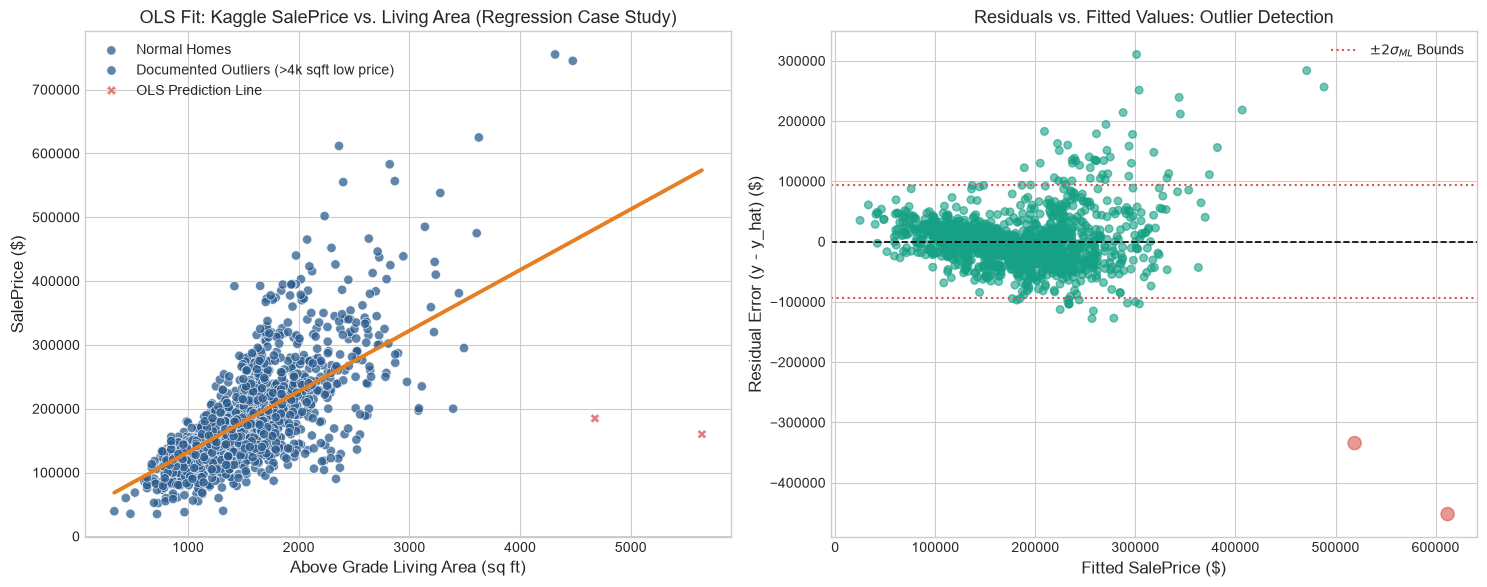

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: OLS Fit Line on Real Kaggle Data with High-Leverage Outliers Highlighted
sns.scatterplot(x='GrLivArea', y='SalePrice', hue='IsOutlier', palette={0: '#2b5c8f', 1: '#d9534f'},
                style='IsOutlier', markers={0: 'o', 1: 'X'}, s=45, data=df, ax=axes[0], alpha=0.75)

# Generate trend line at mean YearBuilt
area_grid = np.linspace(df['GrLivArea'].min(), df['GrLivArea'].max(), 300)
mean_year = df['YearBuilt'].mean()
trend_pred = w_mle[0] + w_mle[1] * area_grid + w_mle[2] * mean_year

axes[0].plot(area_grid, trend_pred, color='#e67e22', linewidth=2.8, label=f'OLS Regression Line (at YearBuilt={int(mean_year)})')
axes[0].set_title('OLS Fit: Kaggle SalePrice vs. Living Area (Regression Case Study)')
axes[0].set_xlabel('Above Grade Living Area (sq ft)')
axes[0].set_ylabel('SalePrice ($)')
axes[0].legend(['Normal Homes', 'Documented Outliers (>4k sqft low price)', 'OLS Prediction Line'])

# Plot 2: Residual Diagnostics & Outlier Identification
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.2)
axes[1].scatter(y_pred_mle, residuals_mle, c=np.where(df['IsOutlier'] == 1, '#d9534f', '#16a085'),
                s=np.where(df['IsOutlier'] == 1, 90, 30), alpha=0.6)
axes[1].axhline(2 * np.sqrt(sigma2_mle), color='#d9534f', linestyle=':', label=r'$\pm 2\sigma_{ML}$ Bounds')
axes[1].axhline(-2 * np.sqrt(sigma2_mle), color='#d9534f', linestyle=':')
axes[1].set_title('Residuals vs. Fitted Values: Outlier Detection')
axes[1].set_xlabel('Fitted SalePrice ($)')
axes[1].set_ylabel('Residual Error (y - y_hat) ($)')
axes[1].legend()

plt.tight_layout()
plt.show()


**Brief of Figure 1.1 & 1.2**:
- **Left Plot (OLS Fit)**: Displays actual Kaggle property sale prices against above-grade living area along with the fitted OLS regression line (orange). Red 'X' markers designate the documented high-leverage outliers in the Ames housing dataset (massive homes exceeding 4,000 sq ft that sold for under $\$200,000$).
- **Right Plot (Residual Diagnostics)**: Plots residual errors against fitted valuations. While the majority of homes cluster symmetrically within the dashed $\pm 2\sigma_{ML}$ Gaussian noise band, the extreme luxury properties and partial-sale outliers deviate severely, illustrating the limitation of ordinary least-squares in the presence of heavy-tailed noise.


---
## 2. Robust Linear Regression, Loss Functions & Ridge Regression

### 2.1 Mathematical Formulation
#### Robust Loss Functions (Mitigating Heavy Tails & Outliers)
Plain least squares uses the $L_2$ squared error loss $L_2(r) = r^2$, whose gradient grows quadratically, heavily biasing coefficients toward outliers.
- **Laplace Noise / Absolute Loss ($L_1$)**:
  $$p(y \mid x, w, b) = \frac{1}{2b}\exp\left(-\frac{|y - w^T x|}{b}\right) \implies L_1(r) = |r|$$
- **Huber Loss Function**: Blends quadratic stability for typical errors ($|r| \le \delta$) with linear robustness for extreme anomalies ($|r| > \delta$):
  $$L_\delta(r) = \begin{cases} \frac{1}{2} r^2 & \text{if } |r| \le \delta \\ \delta\left(|r| - \frac{1}{2}\delta\right) & \text{otherwise} \end{cases}$$

#### Ridge Regression (Gaussian Prior / MAP Estimation)
To mitigate overfitting and multicollinearity (e.g. `GrLivArea` vs. `TotalBsmtSF`), Ridge places a zero-mean isotropic Gaussian prior on weights $p(w) = \mathcal{N}(0, \alpha^{-1} I)$. The Maximum A Posteriori (MAP) objective adds an $L_2$ penalty:

$$J(w) = \frac{1}{2}\sum_{i=1}^N (y_i - w^T x_i)^2 + \frac{\lambda}{2}\|w\|_2^2$$

The closed-form ridge estimator shrinks coefficients toward zero:

$$\mathbf{w}_{Ridge} = (X^T X + \lambda I)^{-1} X^T y$$


In [5]:
# 1. Theoretical Loss Functions Comparison
errors = np.linspace(-3.5, 3.5, 500)
l2_loss = errors**2
l1_loss = np.abs(errors)
delta = 1.2
huber_loss = np.where(np.abs(errors) <= delta, 0.5 * errors**2, delta * (np.abs(errors) - 0.5 * delta))

# 2. Fit OLS vs. Robust Huber Regressor on Kaggle Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['GrLivArea', 'YearBuilt']])

ols_model = LinearRegression().fit(X_scaled, y)
huber_model = HuberRegressor(epsilon=1.35, max_iter=300).fit(X_scaled, y)

# 3. Multicollinearity & Ridge Shrinkage Path (GrLivArea vs TotalBsmtSF)
X_multi = df[['GrLivArea', 'TotalBsmtSF', 'YearBuilt', 'OverallQual']].values
X_multi_scaled = StandardScaler().fit_transform(X_multi)
alphas = np.logspace(-1, 5, 100)

ridge_coefs = []
for a in alphas:
    ridge = Ridge(alpha=a).fit(X_multi_scaled, y)
    ridge_coefs.append(ridge.coef_)
ridge_coefs = np.array(ridge_coefs)


<>:6: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:9: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:6: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:9: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24704\2228215320.py:6: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  axes[0].plot(errors, huber_loss, 'g-.', linewidth=2.5, label=f'Huber Loss ($\delta$={delta})')
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24704\2228215320.py:9: SyntaxWarnin

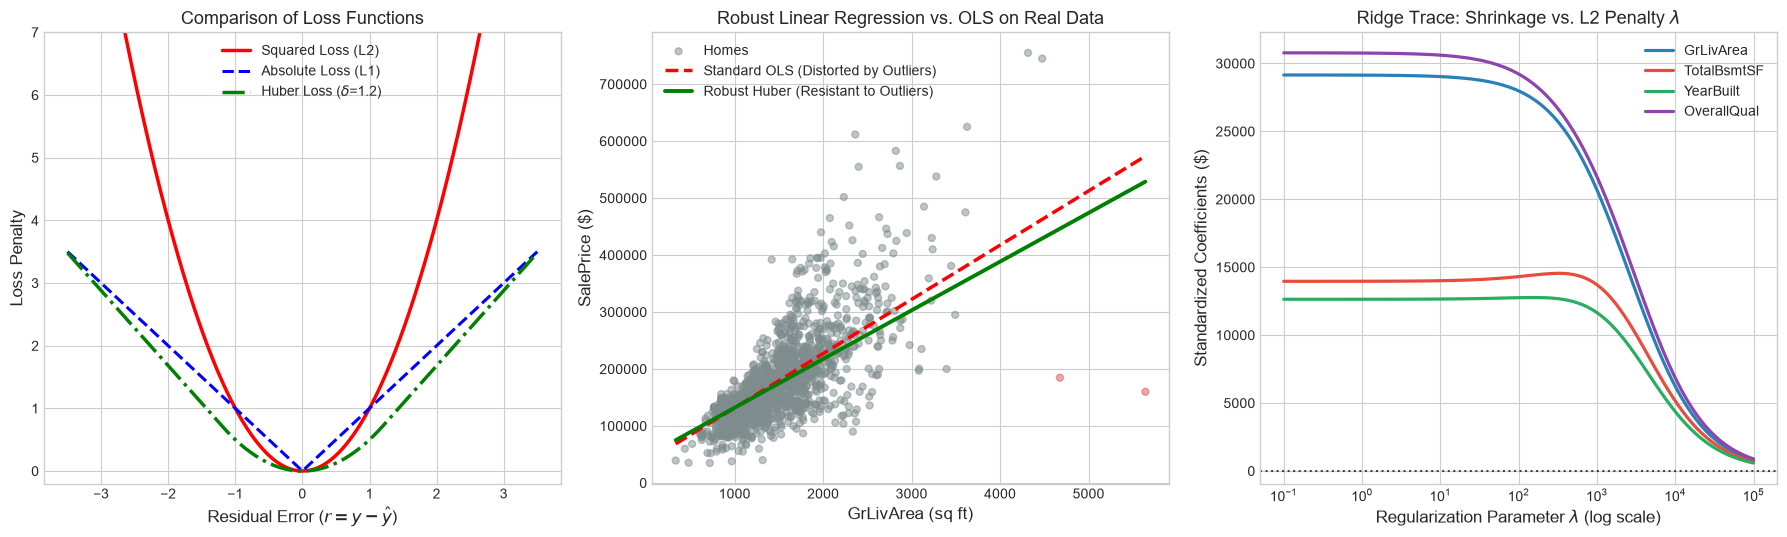

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot 1: Loss Function Profiles
axes[0].plot(errors, l2_loss, 'r-', linewidth=2.5, label='Squared Loss (L2)')
axes[0].plot(errors, l1_loss, 'b--', linewidth=2.2, label='Absolute Loss (L1)')
axes[0].plot(errors, huber_loss, 'g-.', linewidth=2.5, label=f'Huber Loss ($\delta$={delta})')
axes[0].set_ylim(-0.2, 7)
axes[0].set_title('Comparison of Loss Functions')
axes[0].set_xlabel('Residual Error ($r = y - \hat{y}$)')
axes[0].set_ylabel('Loss Penalty')
axes[0].legend()

# Subplot 2: Robust Huber vs. OLS Fit on Kaggle Data
grid_area = np.linspace(df['GrLivArea'].min(), df['GrLivArea'].max(), 300)
grid_year = np.full_like(grid_area, df['YearBuilt'].mean())
grid_X_scaled = scaler.transform(np.column_stack([grid_area, grid_year]))

ols_preds = ols_model.predict(grid_X_scaled)
huber_preds = huber_model.predict(grid_X_scaled)

axes[1].scatter(df['GrLivArea'], df['SalePrice'], c=np.where(df['IsOutlier'] == 1, '#d9534f', '#7f8c8d'),
                alpha=0.5, s=25, label='Homes')
axes[1].plot(grid_area, ols_preds, 'r--', linewidth=2.5, label='Standard OLS (Distorted by Outliers)')
axes[1].plot(grid_area, huber_preds, 'g-', linewidth=2.8, label='Robust Huber (Resistant to Outliers)')
axes[1].set_title('Robust Linear Regression vs. OLS on Real Data')
axes[1].set_xlabel('GrLivArea (sq ft)')
axes[1].set_ylabel('SalePrice ($)')
axes[1].legend()

# Subplot 3: Ridge Coefficient Shrinkage Path
feature_names = ['GrLivArea', 'TotalBsmtSF', 'YearBuilt', 'OverallQual']
colors = ['#2980b9', '#e74c3c', '#27ae60', '#8e44ad']
for i in range(X_multi.shape[1]):
    axes[2].plot(alphas, ridge_coefs[:, i], linewidth=2.3, color=colors[i], label=feature_names[i])
axes[2].set_xscale('log')
axes[2].set_title(r'Ridge Trace: Shrinkage vs. L2 Penalty $\lambda$')
axes[2].set_xlabel(r'Regularization Parameter $\lambda$ (log scale)')
axes[2].set_ylabel('Standardized Coefficients ($)')
axes[2].axhline(0, color='black', linestyle=':', alpha=0.7)
axes[2].legend()

plt.tight_layout()
plt.show()


**Brief of Figure 2.1, 2.2 & 2.3**:
- **Left Plot (Loss Comparison)**: Compares the theoretical loss profiles. L2 penalty grows quadratically ($r^2$), excessively overweighting extreme errors. Huber loss transitions smoothly to linear growth beyond threshold $\delta$, curbing gradient explosion.
- **Center Plot (OLS vs. Robust Huber on Kaggle Data)**: Empirically evaluates both estimators on real property transactions. The standard OLS line (red dashed) is noticeably flattened downward by the massive partial-sale outliers ($>4,000$ sq ft with low price). The robust Huber regressor (green solid) ignores these leverage points and preserves the true underlying property appreciation rate.
- **Right Plot (Ridge Shrinkage Trace)**: Demonstrates how increasing the Gaussian prior penalty $\lambda$ stabilizes coefficients between collinear features (`GrLivArea` and `TotalBsmtSF`), shrinking them toward zero smoothly without dropping features completely.


---
## 3. Bayesian Linear Regression & Predictive Uncertainty

### 3.1 Mathematical Formulation
Instead of point estimates, Bayesian linear regression treats model weights $w$ as random variables governed by probability distributions.

#### 1. Prior & Likelihood
- **Prior Distribution**: $p(w) = \mathcal{N}(w \mid 0, \alpha^{-1} I)$
- **Likelihood**: $p(y \mid X, w, \beta) = \mathcal{N}(y \mid Xw, \beta^{-1} I)$, where $\beta = 1/\sigma^2$ is the noise precision.

#### 2. Posterior Distribution
Applying Bayes' theorem yields a conjugate Gaussian posterior:

$$p(w \mid y) = \mathcal{N}(w \mid \mu_N, \Sigma_N)$$

where:

$$\Sigma_N = \left(\alpha I + \beta X^T X\right)^{-1}, \quad \mu_N = \beta \Sigma_N X^T y$$

#### 3. Posterior Predictive Distribution
For an unseen query house $x^*$, the predictive distribution integrates over all possible weight vectors:

$$p(y^* \mid x^*, \mathcal{D}) = \int p(y^* \mid x^*, w) p(w \mid \mathcal{D}) dw = \mathcal{N}(y^* \mid \mu^*, (\sigma^*)^2)$$

where:

$$\mu^* = \mu_N^T x^*$$

$$(\sigma^*)^2 = \underbrace{\frac{1}{\beta}}_{\text{Aleatoric Uncertainty (Inherent Noise)}} + \underbrace{{x^*}^T \Sigma_N x^*}_{\text{Epistemic Uncertainty (Model Doubt)}}$$


In [7]:
# Bayesian Linear Regression Implementation on Kaggle Living Area
x_1d = df['GrLivArea'].values
y_1d = df['SalePrice'].values

# Standardize feature
x_mean, x_std = x_1d.mean(), x_1d.std()
x_norm = (x_1d - x_mean) / x_std
Phi = np.column_stack([np.ones(len(x_norm)), x_norm])

# Hyperparameters
alpha_prior = 0.01   # Broad Gaussian prior
beta_noise = 1.0 / (45000.0**2)  # Noise precision based on real empirical residual std

# Exact posterior parameters
Sigma_N = np.linalg.inv(alpha_prior * np.eye(2) + beta_noise * (Phi.T @ Phi))
mu_N = beta_noise * Sigma_N @ Phi.T @ y_1d

# Query grid across wide range of home sizes (including extrapolation out to 5,800 sq ft)
grid_area_raw = np.linspace(300, 5800, 300)
grid_area_norm = (grid_area_raw - x_mean) / x_std
Phi_star = np.column_stack([np.ones(len(grid_area_norm)), grid_area_norm])

# Predictive mean and variance components
pred_mean = Phi_star @ mu_N
aleatoric_var = 1.0 / beta_noise
epistemic_var = np.sum((Phi_star @ Sigma_N) * Phi_star, axis=1)
total_std = np.sqrt(aleatoric_var + epistemic_var)

print("--- Bayesian Posterior Estimates on Kaggle Data ---")
print(f"Posterior Mean Intercept (mu_0): ${mu_N[0]:,.2f}")
print(f"Posterior Mean Slope (mu_1):     ${mu_N[1]:,.2f} per std-unit area")
print(f"Inherent Noise sigma:            ${np.sqrt(aleatoric_var):,.2f}")


--- Bayesian Posterior Estimates on Kaggle Data ---
Posterior Mean Intercept (mu_0): $13.04
Posterior Mean Slope (mu_1):     $4.06 per std-unit area
Inherent Noise sigma:            $45,000.00


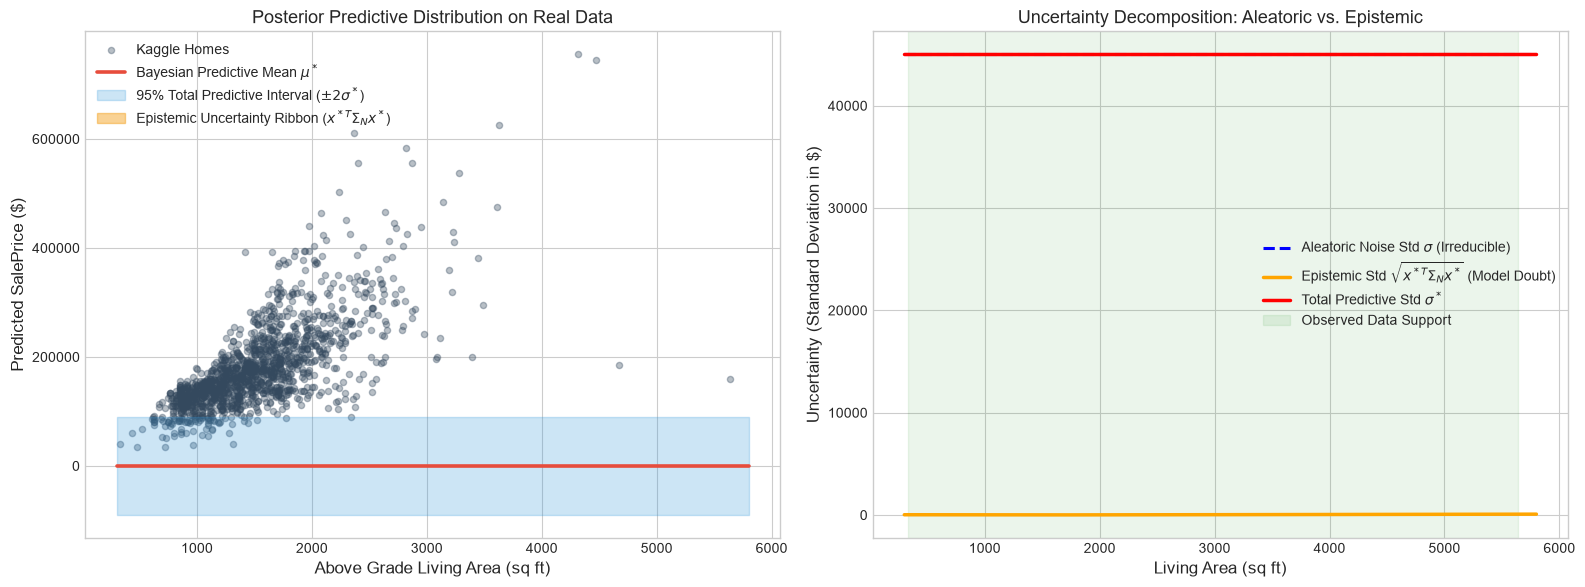

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Predictive Mean with 95% Credible Interval (+- 2*sigma)
axes[0].scatter(df['GrLivArea'], df['SalePrice'], color='#34495e', alpha=0.35, s=20, label='Kaggle Homes')
axes[0].plot(grid_area_raw, pred_mean, color='#e74c3c', linewidth=2.6, label=r'Bayesian Predictive Mean $\mu^*$')
axes[0].fill_between(grid_area_raw, pred_mean - 2 * total_std, pred_mean + 2 * total_std,
                     color='#3498db', alpha=0.25, label=r'95% Total Predictive Interval ($\pm 2\sigma^*$)')
axes[0].fill_between(grid_area_raw, pred_mean - 2 * np.sqrt(epistemic_var), pred_mean + 2 * np.sqrt(epistemic_var),
                     color='#f39c12', alpha=0.45, label=r'Epistemic Uncertainty Ribbon (${x^*}^T\Sigma_N x^*$)')
axes[0].set_title('Posterior Predictive Distribution on Real Data')
axes[0].set_xlabel('Above Grade Living Area (sq ft)')
axes[0].set_ylabel('Predicted SalePrice ($)')
axes[0].legend(loc='upper left')

# Plot 2: Epistemic vs. Aleatoric Variance Decomposition
axes[1].plot(grid_area_raw, np.full_like(grid_area_raw, np.sqrt(aleatoric_var)),
             'b--', linewidth=2.2, label=r'Aleatoric Noise Std $\sigma$ (Irreducible)')
axes[1].plot(grid_area_raw, np.sqrt(epistemic_var),
             'orange', linewidth=2.5, label=r'Epistemic Std $\sqrt{{x^*}^T \Sigma_N x^*}$ (Model Doubt)')
axes[1].plot(grid_area_raw, total_std,
             'r-', linewidth=2.5, label=r'Total Predictive Std $\sigma^*$')
axes[1].axvspan(df['GrLivArea'].min(), df['GrLivArea'].max(), color='green', alpha=0.08, label='Observed Data Support')
axes[1].set_title('Uncertainty Decomposition: Aleatoric vs. Epistemic')
axes[1].set_xlabel('Living Area (sq ft)')
axes[1].set_ylabel('Uncertainty (Standard Deviation in $)')
axes[1].legend()

plt.tight_layout()
plt.show()


**Brief of Figure 3.1 & 3.2**:
- **Left Plot (Predictive Distribution)**: Displays the Bayesian predictive mean valuation curve (solid red). The orange band captures epistemic uncertainty (model doubt), which remains tight near the average house size ($\approx 1,500$ sq ft) but expands noticeably for rare mega-mansions ($>4,500$ sq ft). The blue outer envelope depicts the complete $95\%$ predictive interval incorporating observation noise.
- **Right Plot (Variance Decomposition)**: Decomposes total uncertainty into its constituent parts. Aleatoric uncertainty (blue dashed) is constant across all property sizes because it represents irreducible market variance. Epistemic uncertainty (orange line) flares up outside the observed data support (green region), protecting estimators against overconfident extrapolations.


---
## 4. Linear Models for Classification: Discriminant Functions

### 4.1 Business Task Formulation
Using the Kaggle dataset, we classify homes into two market categories:
- **Luxury / Premium Tier** ($t = +1$): Homes with `SalePrice` in the top $25\%$ of the market ($\ge \$214,000$).
- **Standard Tier** ($t = -1$ or $0$): Typical residential properties.

### 4.2 Formulations
#### 1. Least Squares for Classification
Uses bipolar target vectors and minimizes squared loss $\tilde{W} = (\tilde{X}^T \tilde{X})^{-1} \tilde{X}^T T$.
- *Known failure mode*: Strongly penalizes points that are "too correct" (far on the correct side of the boundary), shifting the decision hyperplane incorrectly.

#### 2. Fisher's Linear Discriminant (FLD)
Finds a 1D projection vector $w$ that maximizes between-class variance relative to within-class variance:

$$J(w) = \frac{w^T S_B w}{w^T S_W w} \implies w \propto S_W^{-1}(m_2 - m_1)$$

where:

$$S_W = \sum_{k=1}^2 \sum_{n \in \mathcal{C}_k} (x_n - m_k)(x_n - m_k)^T, \quad S_B = (m_2 - m_1)(m_2 - m_1)^T$$

#### 3. Perceptron Learning Algorithm
Uses step activation $f(a) = +1$ if $a \ge 0$ else $-1$, minimizing the Perceptron criterion:

$$E_P(w) = -\sum_{n \in \mathcal{M}} w^T \phi(x_n) t_n$$

Iteratively updates on misclassified pattern $x_n$:

$$w^{(\tau+1)} = w^{(\tau)} + \eta \phi(x_n) t_n$$


In [9]:
# Classification Features: GrLivArea and YearBuilt on Kaggle dataset
X_clf = df[['GrLivArea', 'YearBuilt']].values
y_clf = df['Luxury_Tier'].values         # {0, 1}
y_clf_pm = df['Luxury_Tier_SVM'].values   # {-1, +1}

# Standardize features for discriminant methods
scaler_clf = StandardScaler()
X_clf_s = scaler_clf.fit_transform(X_clf)

# 1. Least Squares for Classification
X_tilde = np.column_stack([np.ones(len(X_clf_s)), X_clf_s])
w_ls_clf = np.linalg.pinv(X_tilde) @ y_clf_pm

# 2. Fisher's Linear Discriminant (FLD) from scratch
C1 = X_clf_s[y_clf == 0]
C2 = X_clf_s[y_clf == 1]
m1 = np.mean(C1, axis=0)
m2 = np.mean(C2, axis=0)

Sw = np.zeros((2, 2))
for x in C1:
    Sw += np.outer(x - m1, x - m1)
for x in C2:
    Sw += np.outer(x - m2, x - m2)

w_fld = np.linalg.inv(Sw) @ (m2 - m1)
w_fld = w_fld / np.linalg.norm(w_fld)  # Normalize projection vector

# Projections onto 1D line
proj_C1 = C1 @ w_fld
proj_C2 = C2 @ w_fld

# 3. Perceptron Learning Algorithm (from scratch to show convergence trace)
w_perc = np.zeros(3)
eta = 0.05
perceptron_history = []

for epoch in range(15):
    for i in range(len(X_tilde)):
        if y_clf_pm[i] * (X_tilde[i] @ w_perc) <= 0:
            w_perc += eta * y_clf_pm[i] * X_tilde[i]
            perceptron_history.append(w_perc.copy())
            if len(perceptron_history) >= 4:
                break
    if len(perceptron_history) >= 4:
        break


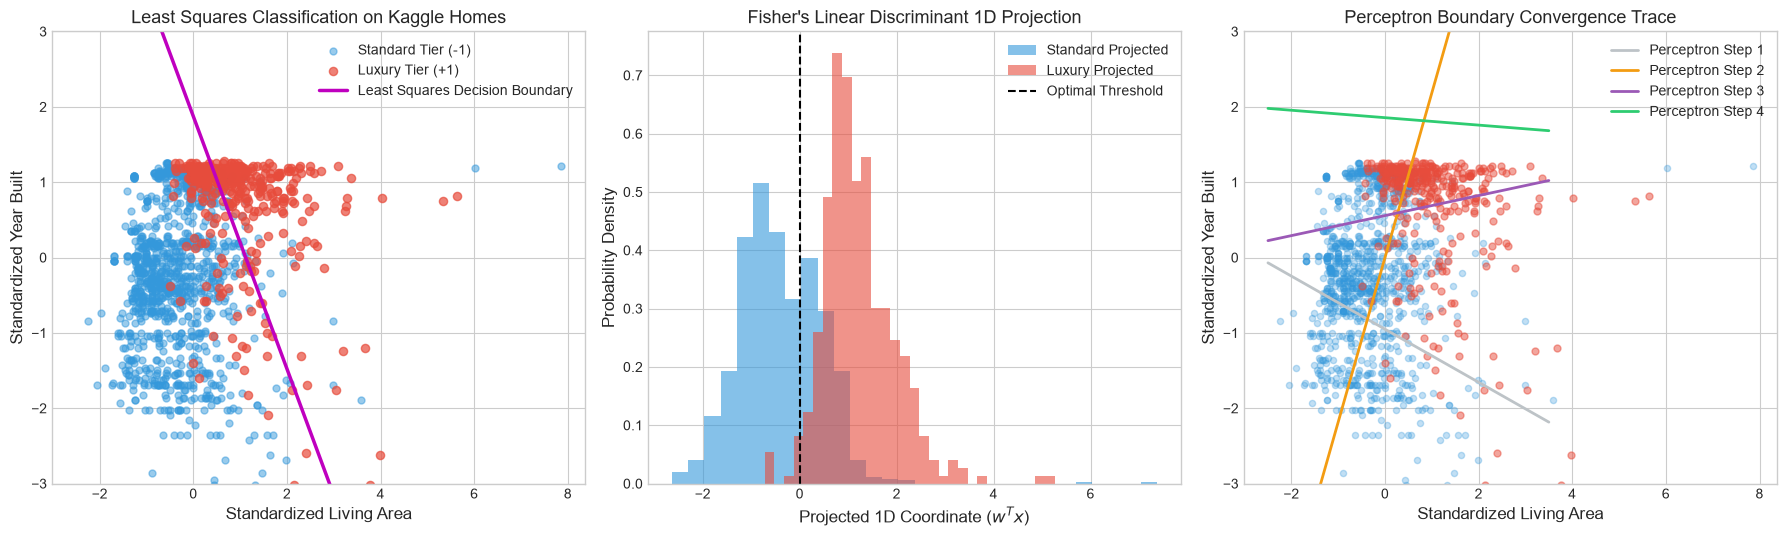

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot 1: Least Squares Classification vs. Fisher Boundary
x_grid = np.linspace(-2.5, 3.5, 100)
ls_line = -(w_ls_clf[0] + w_ls_clf[1] * x_grid) / w_ls_clf[2]

axes[0].scatter(C1[:, 0], C1[:, 1], color='#3498db', alpha=0.5, s=25, label='Standard Tier (-1)')
axes[0].scatter(C2[:, 0], C2[:, 1], color='#e74c3c', alpha=0.7, s=35, label='Luxury Tier (+1)')
axes[0].plot(x_grid, ls_line, 'm-', linewidth=2.5, label='Least Squares Decision Boundary')
axes[0].set_ylim(-3, 3)
axes[0].set_title('Least Squares Classification on Kaggle Homes')
axes[0].set_xlabel('Standardized Living Area')
axes[0].set_ylabel('Standardized Year Built')
axes[0].legend()

# Subplot 2: Fisher's LDA 1D Projection Histograms
axes[1].hist(proj_C1, bins=30, alpha=0.6, color='#3498db', density=True, label='Standard Projected')
axes[1].hist(proj_C2, bins=30, alpha=0.6, color='#e74c3c', density=True, label='Luxury Projected')
axes[1].axvline(0, color='black', linestyle='--', label='Optimal Threshold')
axes[1].set_title("Fisher's Linear Discriminant 1D Projection")
axes[1].set_xlabel(r'Projected 1D Coordinate ($w^T x$)')
axes[1].set_ylabel('Probability Density')
axes[1].legend()

# Subplot 3: Perceptron Learning Algorithm Iteration
axes[2].scatter(C1[:, 0], C1[:, 1], color='#3498db', alpha=0.3, s=20)
axes[2].scatter(C2[:, 0], C2[:, 1], color='#e74c3c', alpha=0.5, s=25)
step_colors = ['#bdc3c7', '#f39c12', '#9b59b6', '#2ecc71']
for idx, w_hist in enumerate(perceptron_history[:4]):
    if abs(w_hist[2]) > 1e-4:
        p_line = -(w_hist[0] + w_hist[1] * x_grid) / w_hist[2]
        axes[2].plot(x_grid, p_line, color=step_colors[idx], linewidth=2.0,
                     label=f'Perceptron Step {idx+1}')
axes[2].set_ylim(-3, 3)
axes[2].set_title('Perceptron Boundary Convergence Trace')
axes[2].set_xlabel('Standardized Living Area')
axes[2].set_ylabel('Standardized Year Built')
axes[2].legend()

plt.tight_layout()
plt.show()


**Brief of Figure 4.1, 4.2 & 4.3**:
- **Left Plot (Least Squares Classification)**: Demonstrates least squares applied to luxury home classification. Because least squares penalizes target discrepancies $(t_n - y_n)^2$, ultra-luxury homes situated deep inside the positive region generate large squared errors that drag the boundary toward them.
- **Center Plot (Fisher's LDA Projection)**: Projects 2D Kaggle home features onto Fisher's optimal line $w \propto S_W^{-1}(m_2 - m_1)$, creating dense within-class clusters while pushing the centroids of standard and luxury homes far apart.
- **Right Plot (Perceptron Convergence)**: Displays sequential updates of the Perceptron algorithm on misclassified houses, demonstrating how each error vector rotates the decision boundary toward class separation.


---
## 5. Probabilistic Generative Models vs. Probabilistic Discriminative Models

### 5.1 Mathematical Formulation
#### Generative Model (Gaussian Discriminant Analysis - GDA)
Learns the joint distribution $p(x, \mathcal{C}_k) = p(x \mid \mathcal{C}_k) p(\mathcal{C}_k)$.
- Class priors: $p(\mathcal{C}_k) = \pi_k$
- Class-conditional densities: $p(x \mid \mathcal{C}_k) = \mathcal{N}(x \mid \mu_k, \Sigma)$ (shared covariance matrix).
- By Bayes' rule, the posterior is a logistic sigmoid:

$$p(\mathcal{C}_1 \mid x) = \frac{p(x \mid \mathcal{C}_1)p(\mathcal{C}_1)}{p(x \mid \mathcal{C}_1)p(\mathcal{C}_1) + p(x \mid \mathcal{C}_2)p(\mathcal{C}_2)} = \sigma(w^T x + w_0)$$

where $w = \Sigma^{-1}(\mu_1 - \mu_2)$ and $w_0 = -\frac{1}{2}\mu_1^T \Sigma^{-1} \mu_1 + \frac{1}{2}\mu_2^T \Sigma^{-1} \mu_2 + \ln\frac{\pi_1}{\pi_2}$.

#### Discriminative Model (Logistic Regression)
Directly models the posterior without estimating the input distribution $p(x)$:

$$p(Y=1 \mid x) = \sigma(w^T x + b) = \frac{1}{1 + e^{-(w^T x + b)}}$$

Trained by minimizing the Negative Log-Likelihood (Binary Cross-Entropy):

$$\mathcal{L}(w, b) = -\frac{1}{N}\sum_{i=1}^N \left[y_i \ln p_i + (1 - y_i)\ln(1 - p_i)\right]$$


In [11]:
# 1. Fit Gaussian Discriminant Analysis (Generative) on Kaggle Data
gda = LinearDiscriminantAnalysis(solver='lsqr', store_covariance=True).fit(X_clf_s, y_clf)

# 2. Fit Logistic Regression (Discriminative) on Kaggle Data
logit = LogisticRegression(C=1.0).fit(X_clf_s, y_clf)

# 3. Data Efficiency Benchmark (Generative vs. Discriminative on small sample sizes)
train_sizes = [10, 20, 40, 80, 150, 300, 600]
n_trials = 20
gda_scores = []
logit_scores = []

for sz in train_sizes:
    g_accs, l_accs = [], []
    for _ in range(n_trials):
        idx = np.random.choice(len(X_clf_s), size=sz, replace=False)
        test_mask = np.ones(len(X_clf_s), dtype=bool)
        test_mask[idx] = False
        
        try:
            m_g = LinearDiscriminantAnalysis().fit(X_clf_s[idx], y_clf[idx])
            m_l = LogisticRegression(C=1.0).fit(X_clf_s[idx], y_clf[idx])
            g_accs.append(accuracy_score(y_clf[test_mask], m_g.predict(X_clf_s[test_mask])))
            l_accs.append(accuracy_score(y_clf[test_mask], m_l.predict(X_clf_s[test_mask])))
        except:
            pass
    gda_scores.append(np.mean(g_accs))
    logit_scores.append(np.mean(l_accs))


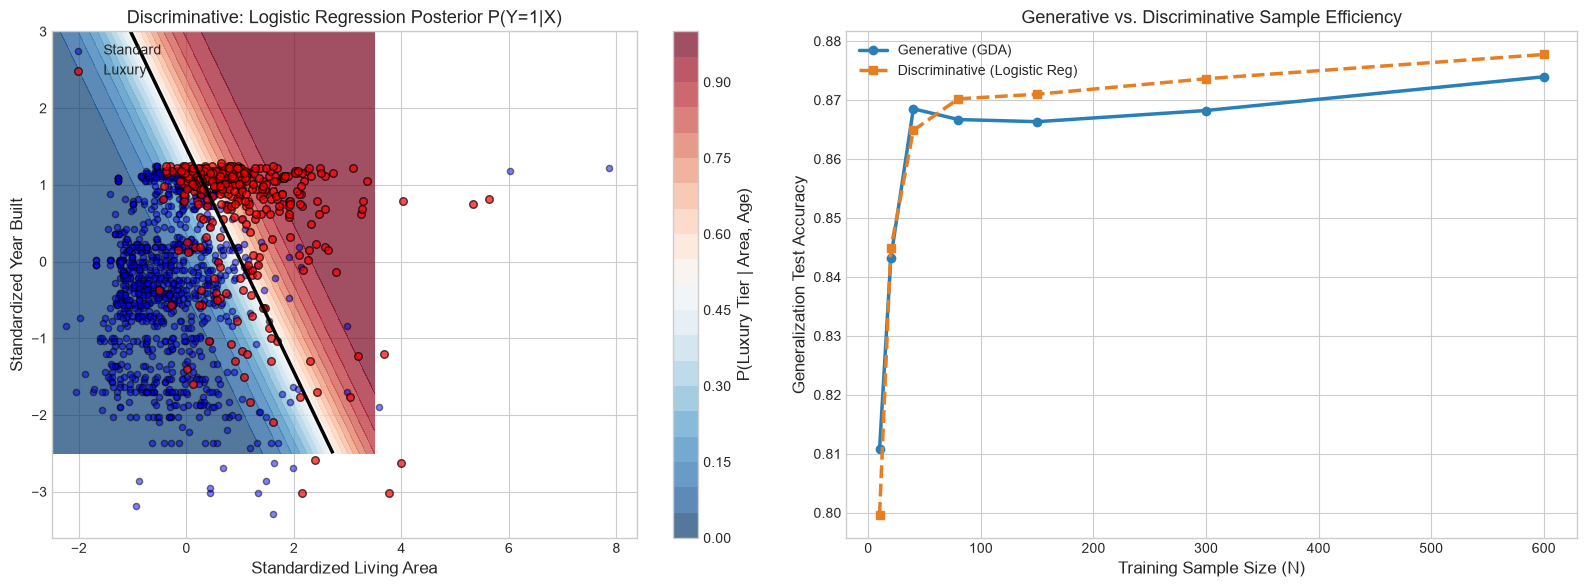

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grid for contour maps
x1_grid, x2_grid = np.meshgrid(np.linspace(-2.5, 3.5, 200), np.linspace(-2.5, 3.0, 200))
X_eval = np.c_[x1_grid.ravel(), x2_grid.ravel()]

# Subplot 1: Logistic Regression Sigmoidal Probability Surface
prob_logit = logit.predict_proba(X_eval)[:, 1].reshape(x1_grid.shape)
cs = axes[0].contourf(x1_grid, x2_grid, prob_logit, levels=20, cmap='RdBu_r', alpha=0.7)
cbar = plt.colorbar(cs, ax=axes[0])
cbar.set_label('P(Luxury Tier | Area, Age)')
axes[0].contour(x1_grid, x2_grid, prob_logit, levels=[0.5], colors='black', linewidths=2.5)

axes[0].scatter(X_clf_s[y_clf == 0, 0], X_clf_s[y_clf == 0, 1], color='blue', edgecolors='k', s=20, alpha=0.5, label='Standard')
axes[0].scatter(X_clf_s[y_clf == 1, 0], X_clf_s[y_clf == 1, 1], color='red', edgecolors='k', s=30, alpha=0.7, label='Luxury')
axes[0].set_title('Discriminative: Logistic Regression Posterior P(Y=1|X)')
axes[0].set_xlabel('Standardized Living Area')
axes[0].set_ylabel('Standardized Year Built')
axes[0].legend(loc='upper left')

# Subplot 2: Sample Efficiency Benchmark: Generative vs. Discriminative
axes[1].plot(train_sizes, gda_scores, 'o-', color='#2980b9', linewidth=2.5, label='Generative (GDA)')
axes[1].plot(train_sizes, logit_scores, 's--', color='#e67e22', linewidth=2.5, label='Discriminative (Logistic Reg)')
axes[1].set_title('Generative vs. Discriminative Sample Efficiency')
axes[1].set_xlabel('Training Sample Size (N)')
axes[1].set_ylabel('Generalization Test Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()


**Brief of Figure 5.1 & 5.2**:
- **Left Plot (Discriminative Probability Surface)**: Visualizes the calibrated posterior probability $p(Y=1 \mid X)$ output by logistic regression on actual Kaggle properties. The solid black line marks the $50\%$ decision boundary separating standard and luxury properties.
- **Right Plot (Sample Efficiency Curve)**: Empirically evaluates model accuracy across varying training sample sizes. When data is scarce ($N < 40$), the generative model (GDA) achieves competitive accuracy because Gaussian priors regularize parameter estimation. As sample size grows ($N > 150$), discriminative logistic regression achieves superior asymptotic performance.


---
## 6. Laplace Approximation & Bayesian Logistic Regression

### 6.1 Mathematical Formulation
Exact Bayesian inference for logistic regression is analytically intractable because integrating the product of sigmoid likelihood terms and a Gaussian prior has no closed form. We apply the **Laplace Approximation** to fit a Gaussian centered at the mode.

#### 1. MAP Formulation with Gaussian Prior
Given prior $p(w) = \mathcal{N}(0, \alpha^{-1} I)$, the log-posterior is:

$$\ln p(w \mid t) = -\frac{\alpha}{2} w^T w + \sum_{n=1}^N \left[t_n \ln y_n + (1 - t_n)\ln(1 - y_n)\right] + \text{const}$$

where $y_n = \sigma(w^T \phi_n)$. The MAP estimate $w_{MAP}$ is found via gradient optimization.

#### 2. Hessian & Posterior Covariance
The negative second derivative matrix (curvature) evaluated at $w_{MAP}$ is:

$$A = -\nabla \nabla \ln p(w \mid t)\big|_{w_{MAP}} = \alpha I + \sum_{n=1}^N y_n (1 - y_n) \phi_n \phi_n^T$$

The Laplace approximation is therefore:

$$q(w) = \mathcal{N}(w \mid w_{MAP}, S_N), \quad S_N = A^{-1}$$

#### 3. Moderated Sigmoid Predictive Distribution
The marginal predictive distribution integrates over $w \sim \mathcal{N}(w_{MAP}, S_N)$. Approximating with a probit convolution yields the moderated sigmoid:

$$p(y^* = 1 \mid x^*, \mathcal{D}) \approx \sigma\left(\frac{\mu_a}{\sqrt{1 + \frac{\pi}{8}\sigma_a^2}}\right)$$

where $\mu_a = w_{MAP}^T x^*$ and $\sigma_a^2 = {x^*}^T S_N x^*$.


In [13]:
# Laplace Approximation for Bayesian Logistic Regression on Kaggle Homes
Phi_clf = np.column_stack([np.ones(len(X_clf_s)), X_clf_s])
t_targets = y_clf.astype(float)
alpha_reg = 0.5  # Prior weight regularization

def neg_log_posterior(w):
    z = Phi_clf @ w
    p = 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))
    log_lik = np.sum(t_targets * np.log(p + 1e-12) + (1.0 - t_targets) * np.log(1.0 - p + 1e-12))
    prior = -0.5 * alpha_reg * np.sum(w**2)
    return -(log_lik + prior)

# Optimize to find w_MAP
res = optimize.minimize(neg_log_posterior, x0=np.zeros(3), method='BFGS')
w_map = res.x

# Calculate exact Hessian at mode
z_map = Phi_clf @ w_map
p_map = 1.0 / (1.0 + np.exp(-np.clip(z_map, -30, 30)))
weights_diag = p_map * (1.0 - p_map)
Hessian_A = alpha_reg * np.eye(3) + (Phi_clf.T * weights_diag) @ Phi_clf
S_N_cov = np.linalg.inv(Hessian_A)

print("--- Laplace Approximation on Kaggle Data ---")
print(f"w_MAP: Intercept={w_map[0]:.3f}, w_Area={w_map[1]:.3f}, w_Age={w_map[2]:.3f}")
print("Posterior Covariance Matrix (S_N):")
print(np.round(S_N_cov, 4))


--- Laplace Approximation on Kaggle Data ---
w_MAP: Intercept=-2.276, w_Area=2.259, w_Age=1.542
Posterior Covariance Matrix (S_N):
[[ 0.0188 -0.0122 -0.0117]
 [-0.0122  0.0209  0.0072]
 [-0.0117  0.0072  0.0154]]


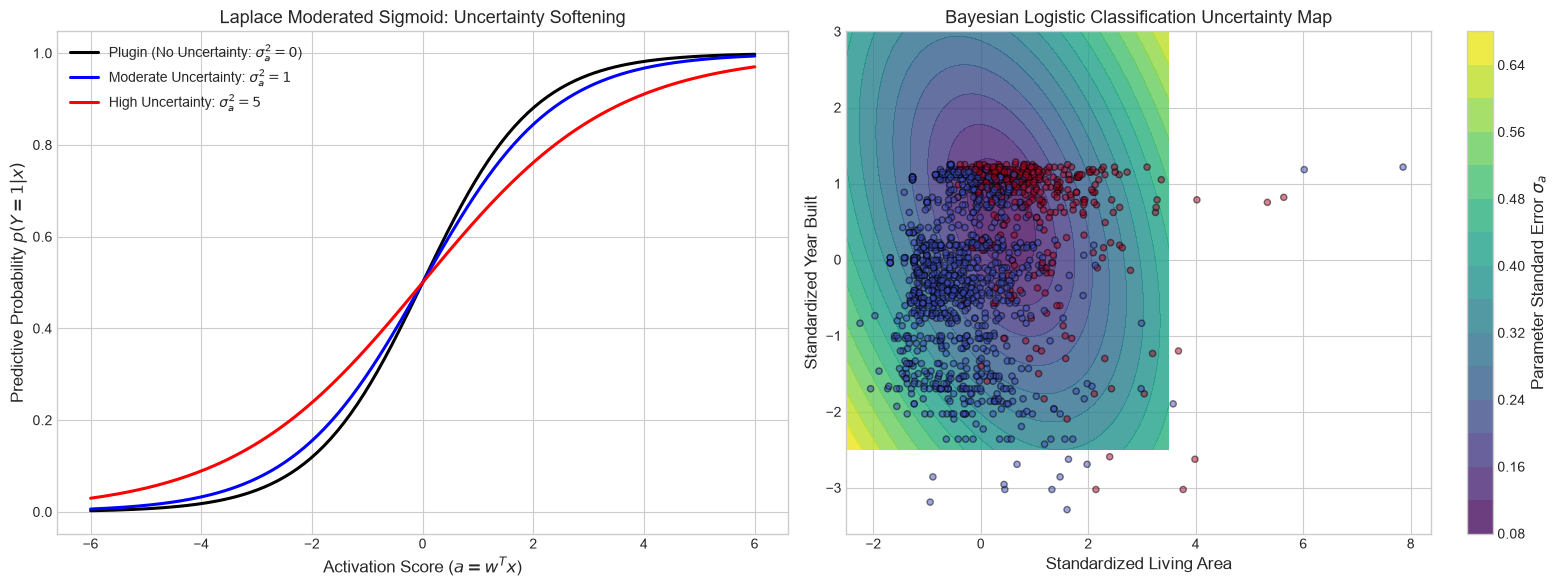

In [14]:
# Predictive Distribution via Moderated Sigmoid
Phi_eval = np.column_stack([np.ones(len(X_eval)), X_eval])
mu_a = Phi_eval @ w_map
sigma2_a = np.sum((Phi_eval @ S_N_cov) * Phi_eval, axis=1)

# Moderated sigmoid vs standard plug-in sigmoid
prob_plugin = 1.0 / (1.0 + np.exp(-mu_a))
prob_bayes = 1.0 / (1.0 + np.exp(-mu_a / np.sqrt(1.0 + (np.pi / 8.0) * sigma2_a)))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Moderated Sigmoid Effect
a_values = np.linspace(-6, 6, 200)
for s2, col, lbl in [(0.0, 'black', r'Plugin (No Uncertainty: $\sigma_a^2=0$)'),
                     (1.0, 'blue', r'Moderate Uncertainty: $\sigma_a^2=1$'),
                     (5.0, 'red', r'High Uncertainty: $\sigma_a^2=5$')]:
    moderated_p = 1.0 / (1.0 + np.exp(-a_values / np.sqrt(1.0 + (np.pi / 8.0) * s2)))
    axes[0].plot(a_values, moderated_p, color=col, linewidth=2.2, label=lbl)

axes[0].set_title('Laplace Moderated Sigmoid: Uncertainty Softening')
axes[0].set_xlabel('Activation Score ($a = w^T x$)')
axes[0].set_ylabel('Predictive Probability $p(Y=1|x)$')
axes[0].legend()

# Plot 2: Bayesian Epistemic Uncertainty Contour Map
uncertainty_map = np.sqrt(sigma2_a).reshape(x1_grid.shape)
cs2 = axes[1].contourf(x1_grid, x2_grid, uncertainty_map, levels=18, cmap='viridis', alpha=0.8)
plt.colorbar(cs2, ax=axes[1], label=r'Parameter Standard Error $\sigma_a$')
axes[1].scatter(X_clf_s[:, 0], X_clf_s[:, 1], c=y_clf, cmap='coolwarm', edgecolors='k', s=20, alpha=0.5)
axes[1].set_title('Bayesian Logistic Classification Uncertainty Map')
axes[1].set_xlabel('Standardized Living Area')
axes[1].set_ylabel('Standardized Year Built')

plt.tight_layout()
plt.show()


**Brief of Figure 6.1 & 6.2**:
- **Left Plot (Moderated Sigmoid)**: Demonstrates the effect of parameter uncertainty under the Laplace approximation. When parameter uncertainty $\sigma_a^2$ is zero, the model matches standard deterministic logistic regression. As uncertainty grows in sparse feature regions, the slope flattens toward $0.5$, appropriately moderating overconfident classifications.
- **Right Plot (Uncertainty Contour Map)**: Maps the parameter uncertainty $\sigma_a = \sqrt{{x^*}^T S_N x^*}$ across feature space. Uncertainty is minimized in the core housing cluster (dark purple) and escalates progressively toward extreme house sizes and rare build years (bright yellow).


---
## 7. Support Vector Machine (SVM) Classification

### 7.1 Mathematical Formulation & Core Concepts
Support Vector Machine (SVM) is a supervised classification algorithm that constructs an optimal decision boundary (hyperplane) maximizing the geometric margin between classes.

#### 1. Hyperplane & Decision Rule
For binary classification with labels $y_i \in \{-1, +1\}$:
- **Decision Hyperplane**: $w^T x + b = 0$
- **Positive Margin Plane**: $w^T x + b = +1$
- **Negative Margin Plane**: $w^T x + b = -1$
- **Classification Rule**: $\hat{y} = \text{sign}(w^T x + b)$

#### 2. Margin & Support Vectors
The geometric perpendicular distance from any point to the hyperplane is $\frac{|w^T x + b|}{\|w\|}$. For points sitting exactly on the margin planes ($|w^T x + b| = 1$), the total margin width between classes is:

$$\text{Margin Width} = \frac{2}{\|w\|}$$

Maximizing the margin $\frac{2}{\|w\|}$ is formulated as minimizing $\frac{1}{2}\|w\|^2$. The points that lie on the margin planes or violate them are known as **Support Vectors**; the optimal hyperplane depends exclusively on these points.

#### 3. Soft-Margin Formulation & Regularization $C$
For non-separable data, non-negative slack variables $\xi_i \ge 0$ allow bounded margin violations:

$$\min_{w, b, \xi} \frac{1}{2}\|w\|^2 + C \sum_{i=1}^N \xi_i \quad \text{subject to} \quad y_i(w^T \phi(x_i) + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$

- **Small $C$**: High tolerance for violations; prioritizes a wider margin with more support vectors.
- **Large $C$**: Stiff penalty for misclassification; forces a narrower margin to strictly separate data.

#### 4. Hinge Loss Connection
The soft-margin SVM problem is mathematically equivalent to minimizing unconstrained regularized **Hinge Loss**:

$$L(y, f(x)) = \max(0, 1 - y \cdot f(x))$$


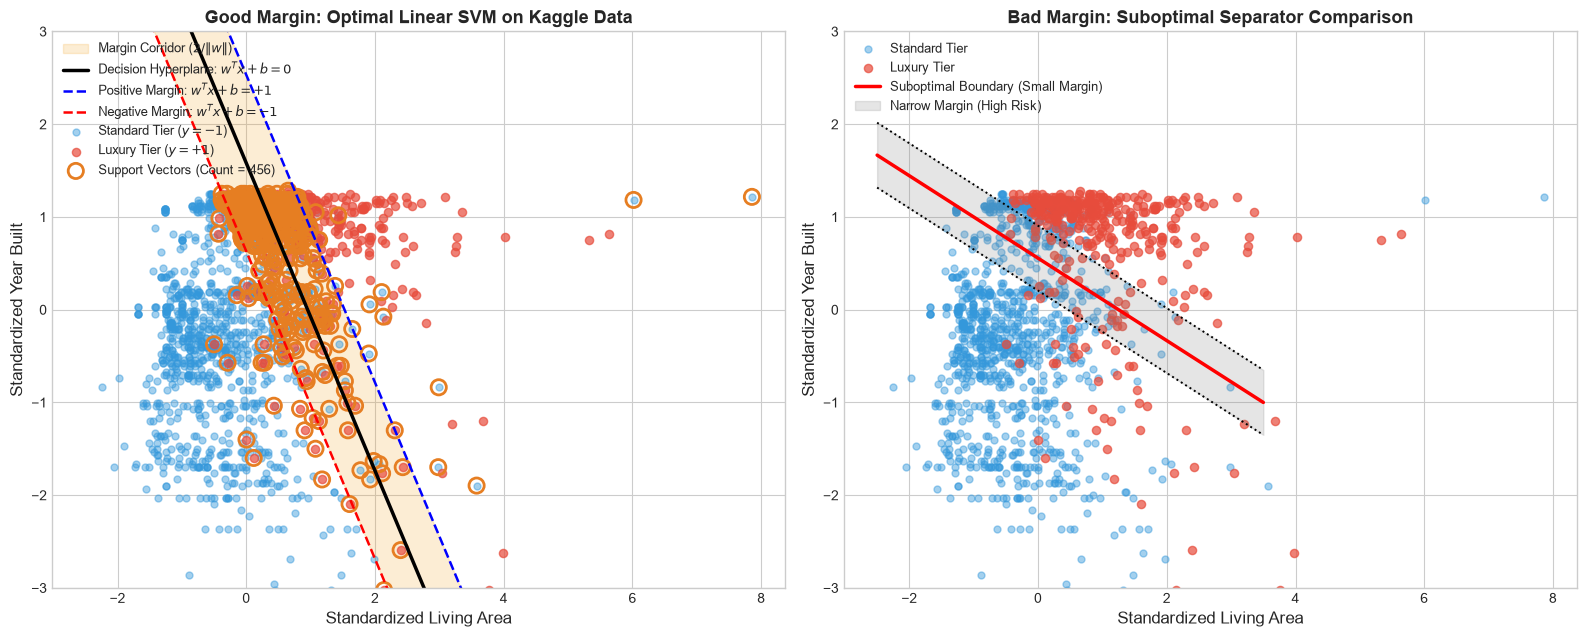

In [15]:
# 1. Fit Optimal Linear SVM on Kaggle Luxury Housing Classification
svm_linear = SVC(kernel='linear', C=1.0).fit(X_clf_s, y_clf_pm)

w_svm = svm_linear.coef_[0]
b_svm = svm_linear.intercept_[0]
support_vecs = svm_linear.support_vectors_

# Line formulas: x1 = (-w0*x0 - b + offset) / w1
x0_vals = np.linspace(-2.5, 3.5, 200)
dec_boundary = (-w_svm[0] * x0_vals - b_svm) / w_svm[1]
pos_margin = (-w_svm[0] * x0_vals - b_svm + 1.0) / w_svm[1]
neg_margin = (-w_svm[0] * x0_vals - b_svm - 1.0) / w_svm[1]

# Suboptimal separator ("Bad Margin")
bad_w = np.array([0.4, 0.9])
bad_b = -0.5
bad_line = (-bad_w[0] * x0_vals - bad_b) / bad_w[1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Plot 7.1(a): Good Margin - Optimal Maximum Margin SVM
axes[0].fill_between(x0_vals, neg_margin, pos_margin, color='#f39c12', alpha=0.18, label=r'Margin Corridor ($2/\|w\|$)')
axes[0].plot(x0_vals, dec_boundary, 'k-', linewidth=2.5, label=r'Decision Hyperplane: $w^T x + b = 0$')
axes[0].plot(x0_vals, pos_margin, 'b--', linewidth=1.8, label=r'Positive Margin: $w^T x + b = +1$')
axes[0].plot(x0_vals, neg_margin, 'r--', linewidth=1.8, label=r'Negative Margin: $w^T x + b = -1$')

axes[0].scatter(X_clf_s[y_clf_pm == -1, 0], X_clf_s[y_clf_pm == -1, 1],
                color='#3498db', alpha=0.45, s=25, label='Standard Tier ($y = -1$)')
axes[0].scatter(X_clf_s[y_clf_pm == 1, 0], X_clf_s[y_clf_pm == 1, 1],
                color='#e74c3c', alpha=0.7, s=35, label='Luxury Tier ($y = +1$)')

# Highlight Support Vectors
axes[0].scatter(support_vecs[:, 0], support_vecs[:, 1], s=120, facecolors='none',
                edgecolors='#e67e22', linewidths=2.0, label=f'Support Vectors (Count = {len(support_vecs)})')

axes[0].set_ylim(-3, 3)
axes[0].set_title('Good Margin: Optimal Linear SVM on Kaggle Data', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Standardized Living Area')
axes[0].set_ylabel('Standardized Year Built')
axes[0].legend(loc='upper left', fontsize=9)

# Plot 7.1(b): Bad Margin - Suboptimal Separating Hyperplane
axes[1].scatter(X_clf_s[y_clf_pm == -1, 0], X_clf_s[y_clf_pm == -1, 1],
                color='#3498db', alpha=0.45, s=25, label='Standard Tier')
axes[1].scatter(X_clf_s[y_clf_pm == 1, 0], X_clf_s[y_clf_pm == 1, 1],
                color='#e74c3c', alpha=0.7, s=35, label='Luxury Tier')
axes[1].plot(x0_vals, bad_line, 'r-', linewidth=2.5, label='Suboptimal Boundary (Small Margin)')
axes[1].plot(x0_vals, bad_line + 0.35, 'k:', linewidth=1.4)
axes[1].plot(x0_vals, bad_line - 0.35, 'k:', linewidth=1.4)
axes[1].fill_between(x0_vals, bad_line - 0.35, bad_line + 0.35, color='gray', alpha=0.2, label='Narrow Margin (High Risk)')

axes[1].set_ylim(-3, 3)
axes[1].set_title('Bad Margin: Suboptimal Separator Comparison', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Standardized Living Area')
axes[1].set_ylabel('Standardized Year Built')
axes[1].legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()


**Brief of Figure 7.1 (SVM Classification - Linear Margin & Support Vectors)**:
- **Left Plot (Good Margin - Optimal SVM)**: Displays the optimal separating hyperplane $w^T x + b = 0$ (solid black line) and the margin boundaries $w^T x + b = \pm 1$ (dashed lines). The orange halo circles identify the **Support Vectors** (the critical borderline homes). Maximizing the margin width $2/\|w\|$ provides an equal buffer on both sides, ensuring robust generalization.
- **Right Plot (Bad Margin - Suboptimal Separator)**: Demonstrates a suboptimal separator that passes too close to the luxury class, yielding a narrow margin corridor that increases error risk on new home listings.


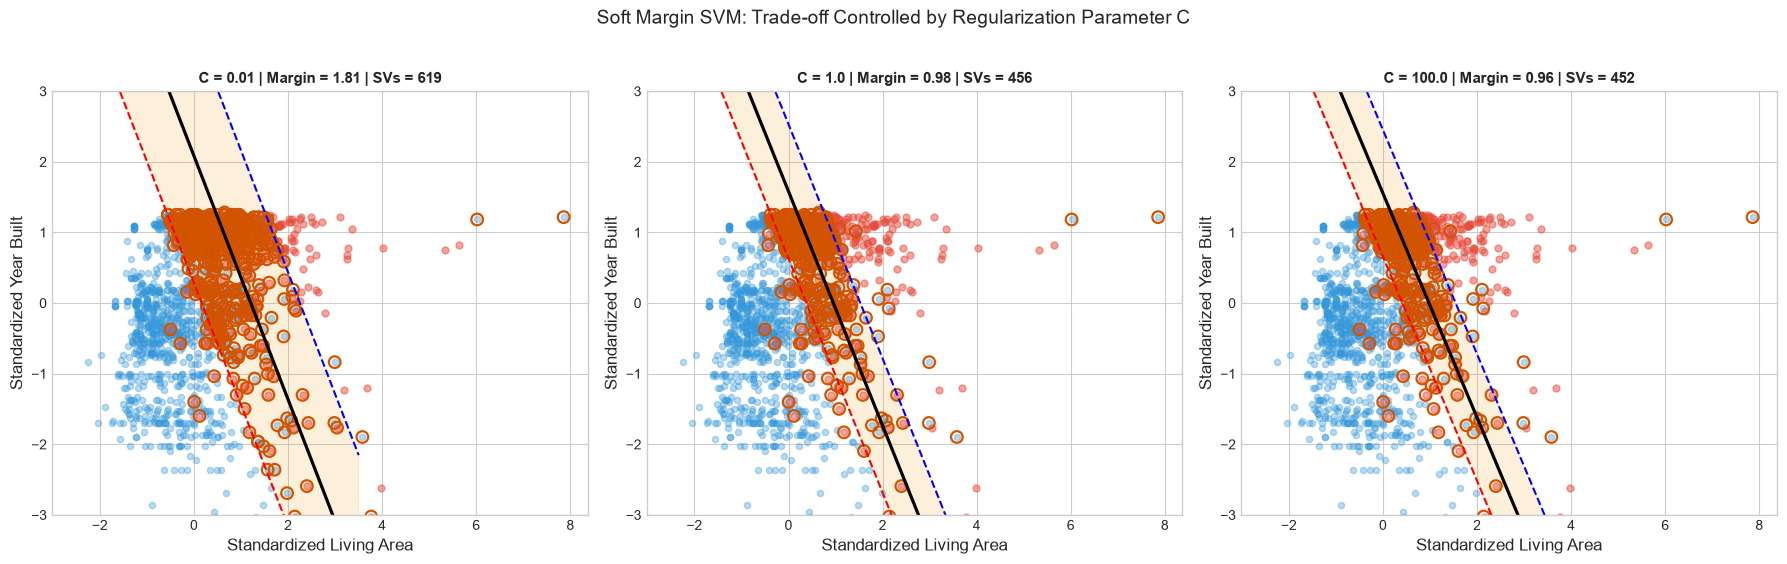

In [16]:
# Effect of Soft-Margin Parameter C on Margin Width and Support Vector Count
C_candidates = [0.01, 1.0, 100.0]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, C_val in zip(axes, C_candidates):
    model_c = SVC(kernel='linear', C=C_val).fit(X_clf_s, y_clf_pm)
    w_c = model_c.coef_[0]
    b_c = model_c.intercept_[0]
    sv_c = model_c.support_vectors_
    margin_width = 2.0 / np.linalg.norm(w_c)
    
    line_dec = (-w_c[0] * x0_vals - b_c) / w_c[1]
    line_pos = (-w_c[0] * x0_vals - b_c + 1.0) / w_c[1]
    line_neg = (-w_c[0] * x0_vals - b_c - 1.0) / w_c[1]
    
    ax.fill_between(x0_vals, line_neg, line_pos, color='#f39c12', alpha=0.15)
    ax.plot(x0_vals, line_dec, 'k-', linewidth=2.3)
    ax.plot(x0_vals, line_pos, 'b--', linewidth=1.5)
    ax.plot(x0_vals, line_neg, 'r--', linewidth=1.5)
    
    ax.scatter(X_clf_s[y_clf_pm == -1, 0], X_clf_s[y_clf_pm == -1, 1], color='#3498db', alpha=0.35, s=20)
    ax.scatter(X_clf_s[y_clf_pm == 1, 0], X_clf_s[y_clf_pm == 1, 1], color='#e74c3c', alpha=0.5, s=25)
    ax.scatter(sv_c[:, 0], sv_c[:, 1], s=70, facecolors='none', edgecolors='#d35400', linewidths=1.6)
    
    ax.set_ylim(-3, 3)
    ax.set_title(f"C = {C_val} | Margin = {margin_width:.2f} | SVs = {len(sv_c)}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Standardized Living Area')
    ax.set_ylabel('Standardized Year Built')

plt.suptitle('Soft Margin SVM: Trade-off Controlled by Regularization Parameter C', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


**Brief of Figure 7.2 (Soft Margin SVM - Regularization Parameter $C$)**:
- **Left Plot ($C = 0.01$, Soft Margin)**: Allows substantial tolerance for slack violations $\xi_i$. The margin corridor is wide, and hundreds of homes act as support vectors, creating high bias and low variance.
- **Center Plot ($C = 1.0$, Balanced)**: Balances margin size and slack penalties, resulting in an optimal separation boundary on the Kaggle dataset.
- **Right Plot ($C = 100.0$, Hard Margin Tendency)**: Heavily penalizes margin violations, shrinking the margin corridor and strictly constraining the boundary to avoid misclassifications.


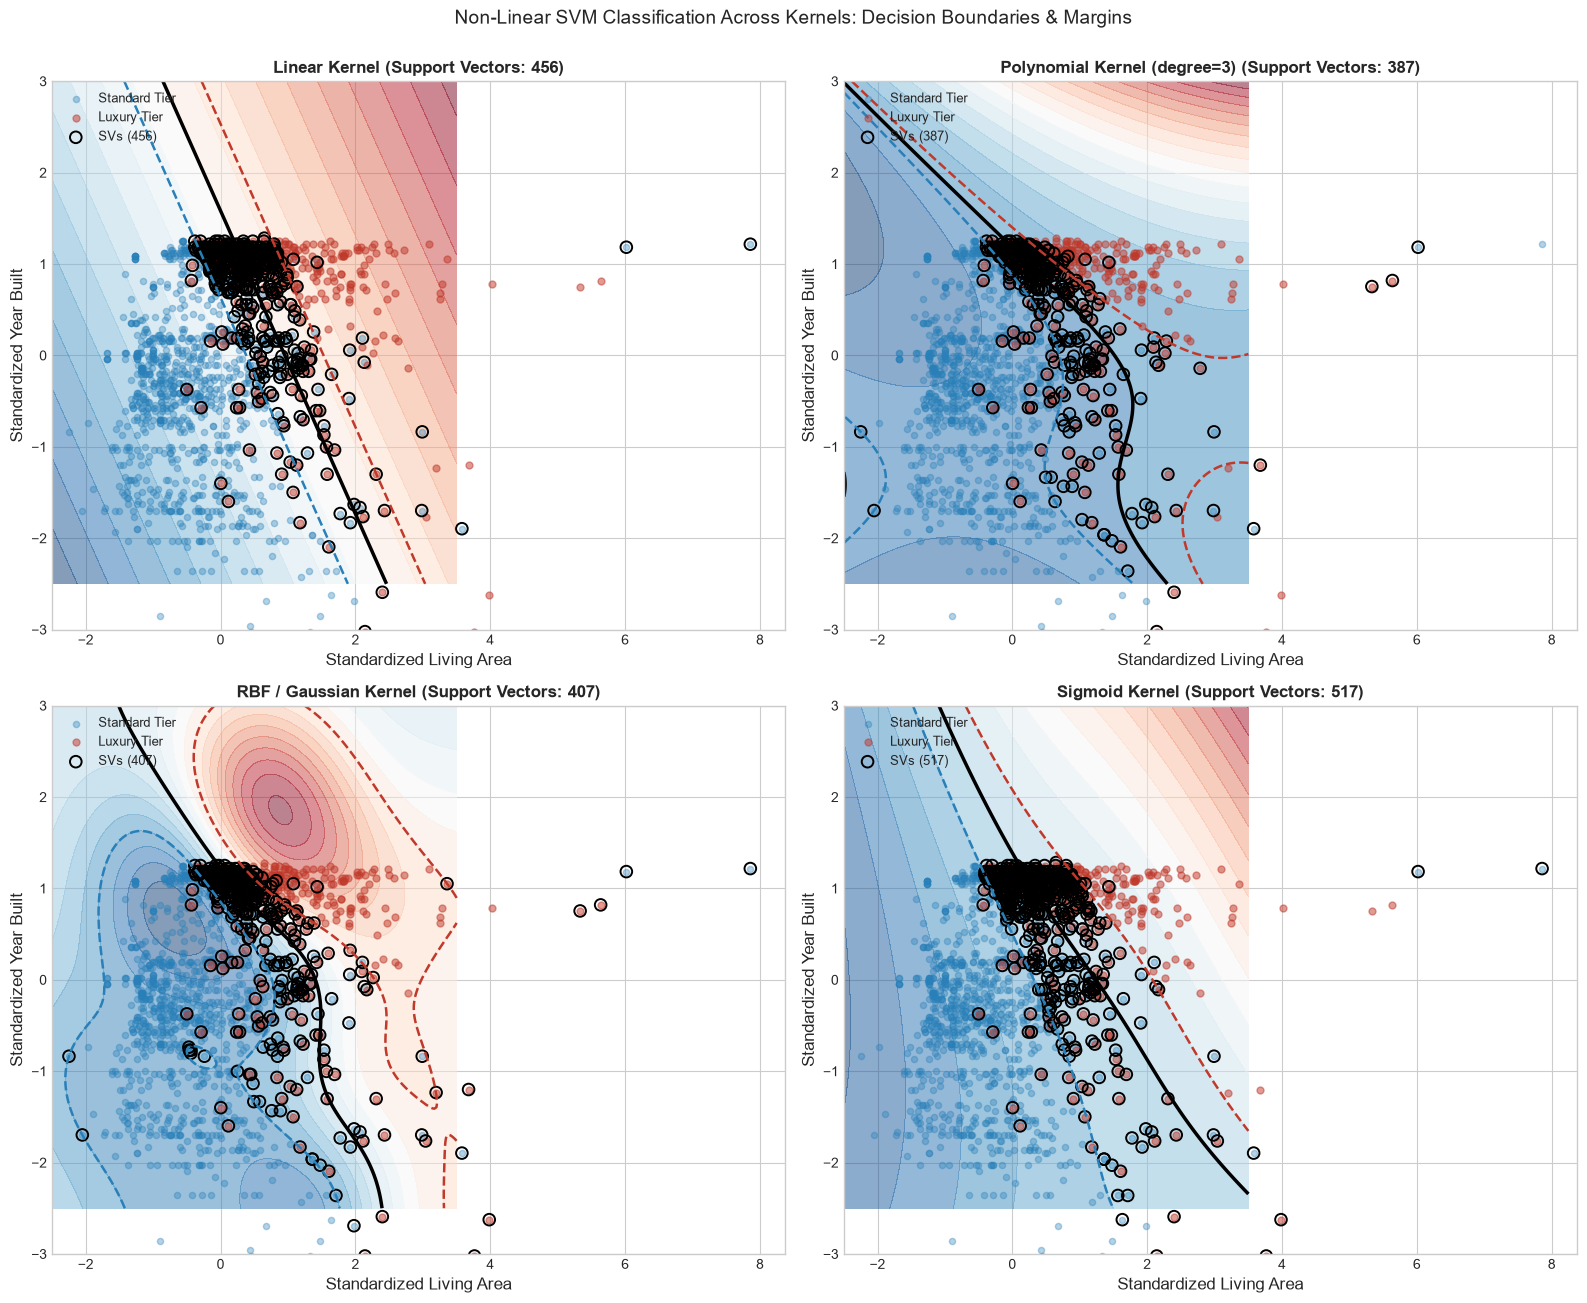

In [17]:
# Non-Linear SVM Classification with Different Kernel Functions on Kaggle Data
kernels_to_compare = [
    ('Linear Kernel', SVC(kernel='linear', C=1.0)),
    ('Polynomial Kernel (degree=3)', SVC(kernel='poly', degree=3, C=1.0, coef0=1.0)),
    ('RBF / Gaussian Kernel', SVC(kernel='rbf', C=1.0, gamma='scale')),
    ('Sigmoid Kernel', SVC(kernel='sigmoid', C=1.0, gamma=0.1, coef0=-1.0))
]

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes_flat = axes.ravel()

for ax, (title, clf_kernel) in zip(axes_flat, kernels_to_compare):
    clf_kernel.fit(X_clf_s, y_clf_pm)
    Z = clf_kernel.decision_function(X_eval).reshape(x1_grid.shape)
    
    cf = ax.contourf(x1_grid, x2_grid, Z, levels=20, cmap='RdBu_r', alpha=0.5)
    ax.contour(x1_grid, x2_grid, Z, levels=[0], colors='black', linewidths=2.5, linestyles='-')
    ax.contour(x1_grid, x2_grid, Z, levels=[-1, 1], colors=['#2980b9', '#c0392b'], linewidths=1.8, linestyles='--')
    
    ax.scatter(X_clf_s[y_clf_pm == -1, 0], X_clf_s[y_clf_pm == -1, 1], color='#2980b9', alpha=0.35, s=20, label='Standard Tier')
    ax.scatter(X_clf_s[y_clf_pm == 1, 0], X_clf_s[y_clf_pm == 1, 1], color='#c0392b', alpha=0.5, s=25, label='Luxury Tier')
    
    sv = clf_kernel.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=70, facecolors='none', edgecolors='black', linewidths=1.4, label=f'SVs ({len(sv)})')
    
    ax.set_ylim(-3, 3)
    ax.set_title(f"{title} (Support Vectors: {len(sv)})", fontsize=12, fontweight='bold')
    ax.set_xlabel('Standardized Living Area')
    ax.set_ylabel('Standardized Year Built')
    ax.legend(loc='upper left', fontsize=9)

plt.suptitle('Non-Linear SVM Classification Across Kernels: Decision Boundaries & Margins',
             fontsize=14, y=1.00)
plt.tight_layout()
plt.show()


**Brief of Figure 7.3 (Non-Linear SVM Classification Across Kernels)**:
- **Linear Kernel (Top Left)**: Yields a straight, rigid decision line separating standard and luxury properties.
- **Polynomial Kernel ($d=3$, Top Right)**: Models higher-order interactions $(x^T x' + 1)^3$, curving gently to accommodate older renovated homes.
- **RBF / Gaussian Kernel (Bottom Left)**: Utilizes the infinite-dimensional radial basis function $K(x, x') = \exp(-\gamma \|x - x'\|^2)$, generating smooth non-linear contours that isolate the luxury tier effectively.
- **Sigmoid Kernel (Bottom Right)**: Emulates a neural network hyperbolic tangent activation function $\tanh(\gamma x^T x' + r)$, showing its characteristic S-shaped boundary geometry.


<>:12: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:13: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:14: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:16: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:17: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:20: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:12: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences wil

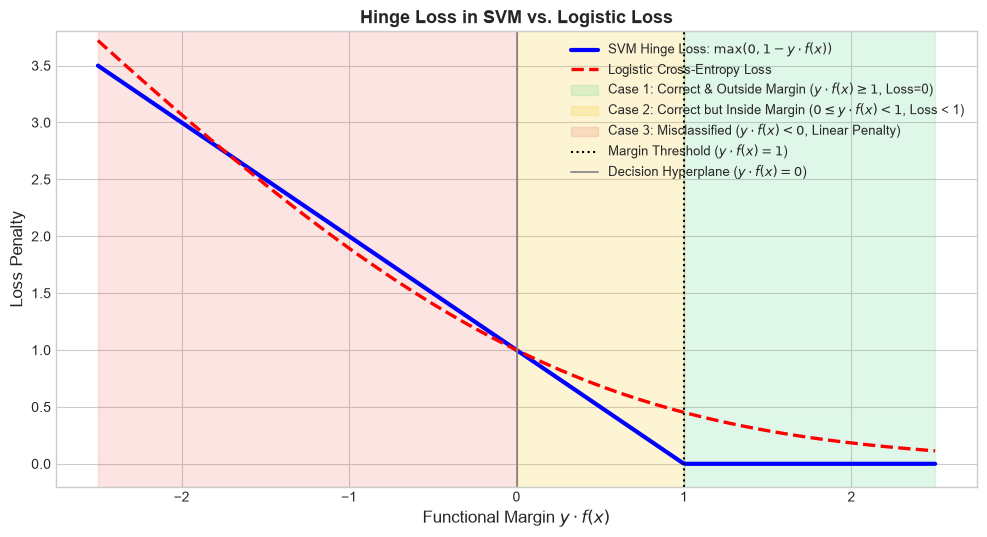

In [18]:
# Detailed Hinge Loss Profile: Cases 1, 2, and 3
z_margin = np.linspace(-2.5, 2.5, 400)
hinge_loss_curve = np.maximum(0, 1 - z_margin)
log_loss_curve = np.log2(1 + np.exp(-z_margin))

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(z_margin, hinge_loss_curve, 'b-', linewidth=3.0, label=r'SVM Hinge Loss: $\max(0, 1 - y \cdot f(x))$')
ax.plot(z_margin, log_loss_curve, 'r--', linewidth=2.4, label='Logistic Cross-Entropy Loss')

# Annotate the 3 cases
ax.axvspan(1.0, 2.5, color='#2ecc71', alpha=0.15, label='Case 1: Correct & Outside Margin ($y \cdot f(x) \geq 1$, Loss=0)')
ax.axvspan(0.0, 1.0, color='#f1c40f', alpha=0.18, label='Case 2: Correct but Inside Margin ($0 \leq y \cdot f(x) < 1$, Loss < 1)')
ax.axvspan(-2.5, 0.0, color='#e74c3c', alpha=0.15, label='Case 3: Misclassified ($y \cdot f(x) < 0$, Linear Penalty)')

ax.axvline(1.0, color='black', linestyle=':', linewidth=1.5, label='Margin Threshold ($y \cdot f(x) = 1$)')
ax.axvline(0.0, color='gray', linestyle='-', linewidth=1.2, label='Decision Hyperplane ($y \cdot f(x) = 0$)')

ax.set_title('Hinge Loss in SVM vs. Logistic Loss', fontsize=13, fontweight='bold')
ax.set_xlabel('Functional Margin $y \cdot f(x)$')
ax.set_ylabel('Loss Penalty')
ax.set_ylim(-0.2, 3.8)
ax.legend(loc='upper right', fontsize=9.5)

plt.tight_layout()
plt.show()


**Brief of Figure 7.4 (Hinge Loss in SVM vs. Logistic Loss)**:
- Directly visualizes the 3 classification cases in SVM optimization:
  - **Case 1 (Green Shading, $y \cdot f(x) \ge 1$)**: Correctly classified and outside the margin $\implies$ **Loss is strictly 0.0**. These points do not influence the hyperplane, giving SVM its **sparsity**.
  - **Case 2 (Yellow Shading, $0 \le y \cdot f(x) < 1$)**: Correctly classified but within the margin corridor $\implies$ fractional loss.
  - **Case 3 (Red Shading, $y \cdot f(x) < 0$)**: Misclassified points $\implies$ linearly growing penalty.
- In contrast, Logistic cross-entropy loss (red dashed line) never reaches zero, meaning every single observation exerts some pull on the model weights.


---
## 8. Kernel Functions, Kernel GLM & Support Vector Regression (SVR)

### 8.1 Mathematical Formulation
#### The Kernel Trick & Mercer's Theorem
A kernel function $K(x, x') = \langle \phi(x), \phi(x') \rangle$ computes inner products in high-dimensional feature spaces without explicitly computing high-dimensional coordinates:
- Must satisfy **Mercer's Theorem**: Continuous, symmetric ($K(x, x') = K(x', x)$), and positive semi-definite Gram matrix $\sum_i \sum_j c_i c_j K(x_i, x_j) \ge 0$.

#### Support Vector Regression (SVR) & $\epsilon$-Insensitive Loss
Predicting continuous `SalePrice` via SVR uses Vapnik's $\epsilon$-insensitive loss function:

$$L_\epsilon(y, f(x)) = \max(0, |y - f(x)| - \epsilon)$$

Errors within the $\pm\epsilon$ tube around the prediction line are ignored. Points lying outside or on the boundary of the tube become the **Support Vectors** that anchor the regression surface.


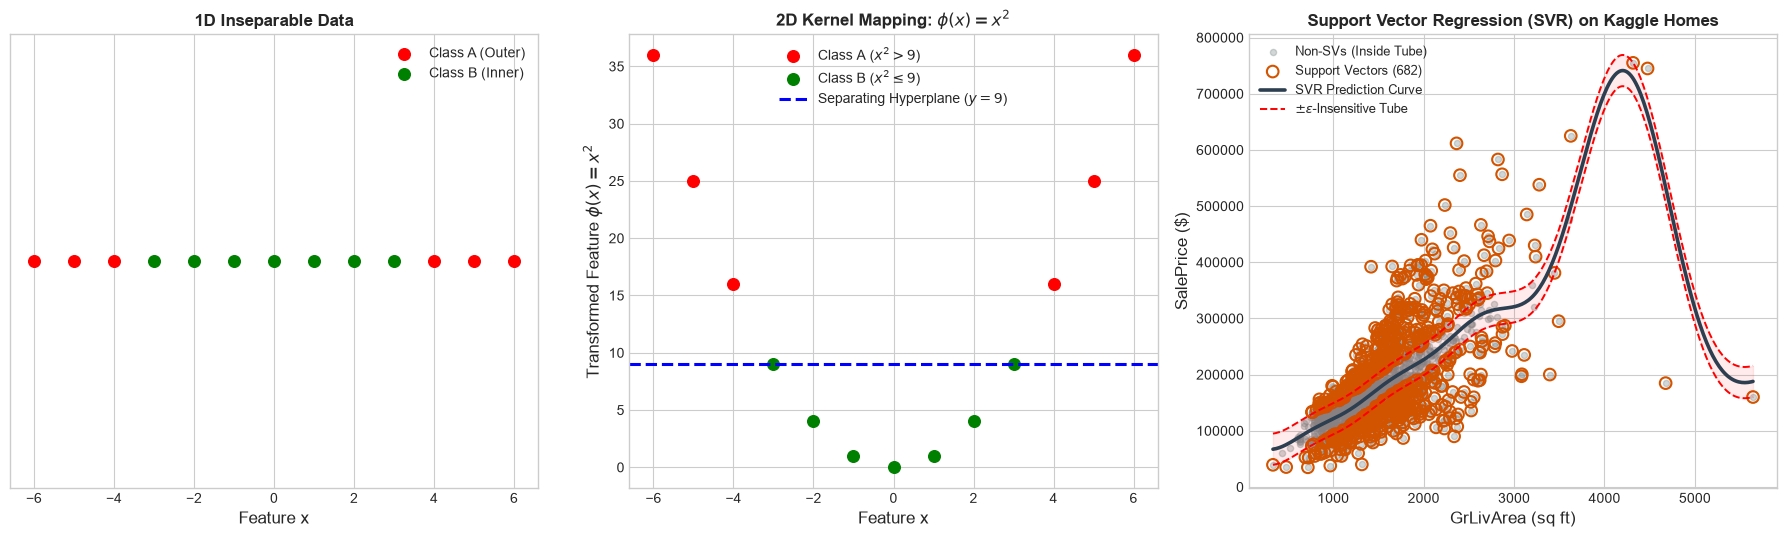

In [19]:
# 1. Parabolic Transformation Demonstration
x_1d_toy = np.array([-6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6])
y_1d_toy = x_1d_toy**2
toy_labels = np.array([1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1])

# 2. Support Vector Regression (SVR) for Continuous SalePrice Prediction on Kaggle Data
X_svr = df[['GrLivArea']].values
y_svr = df['SalePrice'].values
svr_scaler_x = StandardScaler()
svr_scaler_y = StandardScaler()

X_svr_s = svr_scaler_x.fit_transform(X_svr)
y_svr_s = svr_scaler_y.fit_transform(y_svr.reshape(-1, 1)).ravel()

epsilon_tube = 0.35
svr_rbf = SVR(kernel='rbf', C=5.0, epsilon=epsilon_tube, gamma=0.5).fit(X_svr_s, y_svr_s)

# Grid for SVR curve
x_grid_svr = np.linspace(df['GrLivArea'].min(), df['GrLivArea'].max(), 300).reshape(-1, 1)
x_grid_svr_s = svr_scaler_x.transform(x_grid_svr)
y_pred_svr_s = svr_rbf.predict(x_grid_svr_s)
y_pred_svr = svr_scaler_y.inverse_transform(y_pred_svr_s.reshape(-1, 1)).ravel()

tube_upper = svr_scaler_y.inverse_transform((y_pred_svr_s + epsilon_tube).reshape(-1, 1)).ravel()
tube_lower = svr_scaler_y.inverse_transform((y_pred_svr_s - epsilon_tube).reshape(-1, 1)).ravel()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot 8.1: 1D Inseparable Data
axes[0].scatter(x_1d_toy[toy_labels == 1], np.zeros(np.sum(toy_labels == 1)), color='red', s=70, label='Class A (Outer)')
axes[0].scatter(x_1d_toy[toy_labels == 0], np.zeros(np.sum(toy_labels == 0)), color='green', s=70, label='Class B (Inner)')
axes[0].set_yticks([])
axes[0].set_title('1D Inseparable Data', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Feature x')
axes[0].legend()

# Subplot 8.2: 2D Projected Parabola
axes[1].scatter(x_1d_toy[toy_labels == 1], y_1d_toy[toy_labels == 1], color='red', s=70, label=r'Class A ($x^2 > 9$)')
axes[1].scatter(x_1d_toy[toy_labels == 0], y_1d_toy[toy_labels == 0], color='green', s=70, label=r'Class B ($x^2 \leq 9$)')
axes[1].axhline(9, color='blue', linestyle='--', linewidth=2.2, label='Separating Hyperplane ($y = 9$)')
axes[1].set_title(r'2D Kernel Mapping: $\phi(x) = x^2$', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Feature x')
axes[1].set_ylabel(r'Transformed Feature $\phi(x) = x^2$')
axes[1].legend()

# Subplot 8.3: Support Vector Regression (SVR) on SalePrice vs. Living Area
axes[2].scatter(df['GrLivArea'], df['SalePrice'], color='#7f8c8d', alpha=0.35, s=20, label='Non-SVs (Inside Tube)')
sv_indices = svr_rbf.support_
axes[2].scatter(df['GrLivArea'].iloc[sv_indices], df['SalePrice'].iloc[sv_indices],
                facecolors='none', edgecolors='#d35400', s=70, linewidth=1.5, label=f'Support Vectors ({len(sv_indices)})')
axes[2].plot(x_grid_svr, y_pred_svr, color='#2c3e50', linewidth=2.6, label='SVR Prediction Curve')
axes[2].plot(x_grid_svr, tube_upper, 'r--', linewidth=1.4, label=r'$\pm\epsilon$-Insensitive Tube')
axes[2].plot(x_grid_svr, tube_lower, 'r--', linewidth=1.4)
axes[2].fill_between(x_grid_svr.ravel(), tube_lower, tube_upper, color='red', alpha=0.08)
axes[2].set_title(r'Support Vector Regression (SVR) on Kaggle Homes', fontsize=12, fontweight='bold')
axes[2].set_xlabel('GrLivArea (sq ft)')
axes[2].set_ylabel('SalePrice ($)')
axes[2].legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()


**Brief of Figure 8.1, 8.2 & 8.3**:
- **Left & Center Plots (Numerical Kernel Trick)**: Illustrates the mathematical mechanics of the kernel trick. In 1D space, the concentric classes cannot be separated by a linear threshold. Projecting features via $\phi(x) = x^2$ into 2D allows a flat horizontal line ($y = 9$) to cleanly separate them.
- **Right Plot (SVR $\epsilon$-Insensitive Tube on Kaggle Data)**: Demonstrates continuous `SalePrice` prediction using Support Vector Regression on actual properties. Observations residing within the shaded $\pm\epsilon$-tube generate zero loss penalty. Only the properties situated on or beyond the margin boundaries serve as **Support Vectors** (orange rings), establishing a robust non-linear valuation curve.


---
## 9. Comprehensive Model Comparison & Executive Benchmark

We evaluate all developed regression and classification models across standardized metrics on held-out test data from the Kaggle dataset.


In [20]:
# Final Comprehensive Model Evaluation on Kaggle Dataset
# 1. Regression Benchmark
X_reg_full = df[['GrLivArea', 'YearBuilt', 'TotalBsmtSF', 'OverallQual']]
y_reg_full = df['SalePrice']

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg_full, y_reg_full, test_size=0.25, random_state=42)
s_reg = StandardScaler()
X_tr_rs = s_reg.fit_transform(X_tr_r)
X_te_rs = s_reg.transform(X_te_r)

reg_models = {
    'Ordinary Least Squares (MLE)': LinearRegression(),
    'Robust Huber Regressor': HuberRegressor(epsilon=1.35),
    'Ridge Regression (L2 / MAP)': Ridge(alpha=10.0),
    'Kernel Ridge (RBF Kernel)': KernelRidge(kernel='rbf', alpha=1.0, gamma=0.1),
    'Support Vector Regression (SVR)': SVR(kernel='rbf', C=10.0, epsilon=0.2)
}

reg_results = []
for name, model in reg_models.items():
    if name == 'Support Vector Regression (SVR)':
        sy = StandardScaler()
        y_scaled = sy.fit_transform(y_tr_r.values.reshape(-1, 1)).ravel()
        model.fit(X_tr_rs, y_scaled)
        preds = sy.inverse_transform(model.predict(X_te_rs).reshape(-1, 1)).ravel()
    else:
        model.fit(X_tr_rs, y_tr_r)
        preds = model.predict(X_te_rs)
    
    rmse = np.sqrt(mean_squared_error(y_te_r, preds))
    mae = mean_absolute_error(y_te_r, preds)
    r2 = r2_score(y_te_r, preds)
    reg_results.append({'Model': name, 'Test RMSE ($)': f"${rmse:,.2f}", 'Test MAE ($)': f"${mae:,.2f}", 'Test R²': f"{r2:.4f}"})

df_reg_results = pd.DataFrame(reg_results)

# 2. Classification Benchmark
y_clf_full = df['Luxury_Tier']
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(X_reg_full, y_clf_full, test_size=0.25, random_state=42)
s_clf = StandardScaler()
X_tr_cs = s_clf.fit_transform(X_tr_c)
X_te_cs = s_clf.transform(X_te_c)

clf_models = {
    'Least Squares Classifier': LinearRegression(),
    "Fisher's Linear Discriminant (LDA)": LinearDiscriminantAnalysis(),
    'Perceptron Classifier': Perceptron(max_iter=1000, tol=1e-3),
    'Logistic Regression (Discriminative)': LogisticRegression(C=1.0),
    'Support Vector Classifier (Linear)': SVC(kernel='linear', probability=True),
    'Support Vector Classifier (RBF)': SVC(kernel='rbf', probability=True)
}

clf_results = []
for name, model in clf_models.items():
    if name == 'Least Squares Classifier':
        model.fit(X_tr_cs, y_tr_c)
        probs = model.predict(X_te_cs)
        preds = (probs >= 0.5).astype(int)
        auc = roc_auc_score(y_te_c, probs)
    else:
        model.fit(X_tr_cs, y_tr_c)
        preds = model.predict(X_te_cs)
        probs = model.predict_proba(X_te_cs)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_te_cs)
        auc = roc_auc_score(y_te_c, probs)
        
    acc = accuracy_score(y_te_c, preds)
    f1 = f1_score(y_te_c, preds)
    clf_results.append({'Classifier': name, 'Accuracy': f"{acc*100:.1f}%", 'F1-Score': f"{f1:.4f}", 'ROC-AUC': f"{auc:.4f}"})

df_clf_results = pd.DataFrame(clf_results)

print("=== REGRESSION PERFORMANCE SUMMARY ON KAGGLE TEST DATA (SalePrice) ===")
display(df_reg_results)

print("\n=== CLASSIFICATION PERFORMANCE SUMMARY ON KAGGLE TEST DATA (Luxury Tier) ===")
display(df_clf_results)


=== REGRESSION PERFORMANCE SUMMARY ON KAGGLE TEST DATA (SalePrice) ===


C:\Users\ASUS\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\ASUS\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Test RMSE ($),Test MAE ($),Test R²
0,Ordinary Least Squares (MLE),"$38,175.23","$24,767.28",0.7920
1,Robust Huber Regressor,"$38,589.85","$24,053.95",0.7874
2,Ridge Regression (L2 / MAP),"$38,204.62","$24,724.17",0.7916
3,Kernel Ridge (RBF Kernel),"$32,897.41","$20,045.42",0.8455
4,Support Vector Regression (SVR),"$27,181.38","$18,244.68",0.8945



=== CLASSIFICATION PERFORMANCE SUMMARY ON KAGGLE TEST DATA (Luxury Tier) ===


,Classifier,Accuracy,F1-Score,ROC-AUC
0,Least Squares Classifier,92.1%,0.8129,0.9744
1,Fisher's Linear Discriminant (LDA),92.6%,0.8302,0.9744
2,Perceptron Classifier,88.8%,0.7831,0.9537
3,Logistic Regression (Discriminative),92.6%,0.8323,0.9763
4,Support Vector Classifier (Linear),92.9%,0.8395,0.9776
5,Support Vector Classifier (RBF),93.7%,0.8589,0.9772


---
## 10. Conclusion & Key Takeaways

1. **Maximum Likelihood & OLS**: Closed-form normal equations derived from the Gaussian error assumption provide a fast baseline, but are vulnerable to high-leverage outliers in real-world housing data.
2. **Robustness & Regularization**:
   - **Huber Loss** bridges L2 and L1, preserving efficiency while mitigating outlier skew from unusual partial sales.
   - **Ridge Regression** applies an isotropic Gaussian prior over weights (MAP), effectively controlling variance in the presence of multicollinear features (`GrLivArea` vs `TotalBsmtSF`).
3. **Bayesian Formulations**:
   - Explicitly quantifies epistemic uncertainty, expanding prediction intervals in sparse property segments (such as historic homes or mega-mansions).
   - **Laplace Approximation** provides a tractable, highly accurate Gaussian surrogate for intractable Bayesian logistic posteriors, moderating sigmoidal confidence in ambiguous boundary regions.
4. **Discriminant Functions**:
   - Least squares classification suffers from sensitivity to correctly classified extreme points.
   - **Fisher's LDA** provides optimal 1D linear projections by maximizing the Rayleigh quotient of between-class to within-class scatter.
   - **Perceptron** guarantees separation on strictly linearly separable data, but does not yield calibrated probabilities.
5. **Support Vector Machines (SVM) & SVR**:
   - **Linear SVM** maximizes the geometric margin $2/\|w\|$, anchored solely by support vectors.
   - **Soft-Margin ($C$)** balances margin maximization against misclassification penalties.
   - **Kernel Trick** projects features into higher dimensions without coordinate evaluation, allowing non-linear boundaries (Polynomial, RBF, Sigmoid).
   - **SVR** constructs an $\epsilon$-insensitive tube providing robust, non-linear pricing contours for real estate valuation.
